# <span style=color:crimson>**Part 1:** Imports</span>

In [57]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import ttest_ind, kruskal, spearmanr
import svy

pd.set_option("display.max_columns", None)


In [3]:
#Demogrpahics
demo_df = pd.read_sas('../demographics data/DEMO_L.xpt', format='xport')

#Food Security
fs_df = pd.read_sas('../questionnaire data/quest_FSQ_L.xpt', format='xport')

#Body Measurement
bm_df = pd.read_sas('../examination data/exam_BMX_L.xpt', format = 'xport')

#Income
in_df = pd.read_sas('../questionnaire data/quest_INQ_L.xpt', format = 'xport')

#Total Nutrient Intake Day 1
nut1_df = pd.read_sas('../dietary data/diet_DR1TOT_L.xpt', format= 'xport')

#Total Nutrient Day 2
nut2_df = pd.read_sas('../dietary data/diet_DR2TOT_L.xpt', format='xport')

#will need to get rid of special missing values that Pandas has converted to a near-zero number
SAS_MISSING_CUTOFF = 1e-20

In [4]:
#Replacing near-zero values with 0
list_of_dfs = [demo_df, fs_df, bm_df, in_df, nut1_df, nut2_df]

for df in list_of_dfs:
    numeric_columns = df.select_dtypes(include = 'number').columns
    near_zero = (df[numeric_columns] > 0) & (df[numeric_columns] < SAS_MISSING_CUTOFF)
    df[numeric_columns] = df[numeric_columns].mask(near_zero, 0)

# <span style=color:crimson>**Part 2:** Filtering</span>

### <span style=color:red>Demographics:</span>

In [5]:
#Filtering Demo. Dataset:
filtered_demo_df = demo_df[["RIDRETH3", "DMDBORN4", "RIDAGEYR", "INDFMPIR", 
                   "DMDEDUC2", "DMDHHSIZ", "RIAGENDR", "DMDMARTZ", "SEQN", "SDMVSTRA","SDMVPSU"]]

In [6]:
#Renaming the Selected Columns:
renamed_demo_df = filtered_demo_df.rename(columns={
    "RIDAGEYR": "Age",
    "RIAGENDR": "Gender",
    "RIDRETH3": "Race",
    "DMDBORN4": "Country_of_Birth",
    "INDFMPIR": "Income_Poverty_Ratio",
    "DMDEDUC2": "Education_Level",
    "DMDHHSIZ": "Total_People_in_Household",
    "DMDMARTZ": "Marital_Status",
    "SEQN": "ID",
    "SDMVSTRA": "Masked_variance_pseudo-stratum",
    "SDMVPSU": "Masked_variance_pseudo-PSU" 
})


### <span style=color:red>Questionnaire:</span>

In [7]:
#Filtering Questionare Dataset:
filtered_fs_df = fs_df[['FSDAD', 'FSD032A', 'FSD032B', 'FSD032C', 'FSD041', 'FSD052', 'FSD061', 'FSD071', 
                        'FSD081', 'FSD092', 'FSD102', 'FSD230', 'FSD151', 'SEQN']]

In [8]:
#Renaming the Selected Columns:
renamed_fs_df = filtered_fs_df.rename(columns= {
    "FSDAD": "Adult_Food_Security", 
    "FSD032A": "Worried_Food_Would_Run_Out",
    "FSD032B": "Food_Didnt_Last",
    "FSD032C": "Cannot_Afford_Balance_Meals",
    "FSD041": "Adults_Who_Skip_Meals",
    "FSD052": "Skipped_Meals_How_Often",
    "FSD061": "Ate_Less_Than_Should",
    "FSD071": "Hungry_and_Didn't_Eat",
    "FSD081": "Lost_Weight",
    "FSD092": "Did_Not_Eat_Whole_Day",
    "FSD102": "Did_Not_Eat_Whole_Day_How_Often",
    "FSD230": "Receiving_Food_Assistaince",
    "FSD151": "Received_Emergency_Food",
    "SEQN": "ID" 
})

In [9]:
#Filtering Income Dataset:
filtered_in_df = in_df[["INDFMMPC","SEQN"]]

In [10]:
#Renaming the Selected Columns:
renamed_in_df = filtered_in_df.rename(columns = {
    "INDFMMPC" : "Family_Monthly_Poverty_Level_Category",
    "SEQN" : "ID"
})

### <span style=color:red>Laboratory:</span>

In [11]:
#Filtering Labratory Dataset:
filtered_bm_df = bm_df[['BMXWT','SEQN']]

In [12]:
#Renaming the Selected Columns:
renamed_bm_df = filtered_bm_df.rename(columns = {
    "BMXWT" : "Weight",
    "SEQN" : "ID"
})

### <span style=color:red>Nutrient/Diet:</span>

In [13]:
#Filtering Dat 1 Total Nutrient Intake Dataset:
filtered_nut1_df = nut1_df[['DR1TKCAL', 'DR1TPROT', 'DR1TCARB', 'DR1TTFAT', 'DR1TSUGR', 'DR1TFIBE', 'DR1TSFAT', 
                            'DR1TMFAT', 'DR1TPFAT', 'DR1TCHOL', 'DR1TFDFE', 'DR1TVB12', 'DR1TVC', 'DR1TVARA', 
                            'DR1TVD', 'DR1TATOC', 'DR1TZINC', 'DR1TCOPP', 'DRQSDT1', 'DRQSDIET', 'WTDRD1', 'DR1DRSTZ', 'SEQN']]

In [14]:
#Filtering Dat 2 Total Nutrient Intake Dataset:
filtered_nut2_df = nut2_df[['DR2TKCAL','DR2TPROT','DR2TCARB','DR2TTFAT','DR2TSUGR','DR2TFIBE','DR2TSFAT',
                            'DR2TMFAT','DR2TPFAT','DR2TCHOL','DR2TVARA','DR2TFDFE','DR2TVB12','DR2TVC','DR2TVD',
                            'DR2TATOC','DR2TZINC', 'DR2TCOPP', 'WTDR2D','DR2DRSTZ','DRDINT','SEQN']]

In [15]:
filtered_nut1_df.shape

(8860, 23)

In [16]:
#the next two code blocks will be filtering out NA values from the nutrition data frames
#the reason for doing this early is because the final data frame only has the average data, and there 
#are missing values in the data frame that are not encoded as NaN.
filtered_nut1_df = filtered_nut1_df.dropna(subset = filtered_nut1_df.columns[0:16])
filtered_nut1_df.shape

(6694, 23)

In [17]:
filtered_nut2_df = filtered_nut2_df.dropna(subset = filtered_nut2_df.columns[0:16])
filtered_nut2_df.shape

(5830, 22)

# <span style=color:crimson>**Part 3:** Merging</span>

In [18]:
#Merging both Nutrient Datasets:
merged_nut_df = pd.merge(
    filtered_nut1_df,
    filtered_nut2_df,
    on='SEQN',
    how='inner'
)

In [19]:
merged_nut_df.head()

,DR1TKCAL,DR1TPROT,DR1TCARB,DR1TTFAT,DR1TSUGR,DR1TFIBE,DR1TSFAT,DR1TMFAT,DR1TPFAT,DR1TCHOL,DR1TFDFE,DR1TVB12,DR1TVC,DR1TVARA,DR1TVD,DR1TATOC,DR1TZINC,DR1TCOPP,DRQSDT1,DRQSDIET,WTDRD1,DR1DRSTZ,SEQN,DR2TKCAL,DR2TPROT,DR2TCARB,DR2TTFAT,DR2TSUGR,DR2TFIBE,DR2TSFAT,DR2TMFAT,DR2TPFAT,DR2TCHOL,DR2TVARA,DR2TFDFE,DR2TVB12,DR2TVC,DR2TVD,DR2TATOC,DR2TZINC,DR2TCOPP,WTDR2D,DR2DRSTZ,DRDINT
0,1740.0,80.46,169.66,55.07,43.71,10.1,21.000,17.040,11.401,274.0,555.0,1.79,22.0,771.0,0.2,4.64,8.78,0.861,NaN,2.0,61366.555827,1.0,130378.0,1040.0,96.59,49.91,39.77,0.41,1.8,9.264,12.967,9.706,308.0,339.0,296.0,7.34,25.0,23.7,8.85,5.05,0.541,70554.222162,1.0,2.0
1,2741.0,86.45,314.86,67.18,113.58,29.6,14.544,19.386,25.622,131.0,415.0,2.89,222.2,213.0,0.4,13.74,10.72,2.044,NaN,2.0,34638.056480,1.0,130379.0,2228.0,78.79,246.02,79.20,113.41,18.7,19.938,28.926,22.651,191.0,486.0,317.0,1.72,124.0,1.5,8.85,9.25,1.546,36505.468348,1.0,2.0
2,1995.0,69.86,281.67,65.38,114.66,21.1,26.936,18.638,11.687,270.0,203.0,2.43,197.3,599.0,5.4,9.00,12.06,0.951,NaN,1.0,84728.261560,1.0,130380.0,1475.0,64.37,208.98,45.99,107.18,21.7,9.912,16.756,13.047,538.0,467.0,174.0,1.51,80.1,2.9,5.98,8.84,1.236,103979.190677,1.0,2.0
3,1676.0,54.11,224.98,63.57,117.83,11.5,22.004,17.342,16.090,188.0,283.0,6.11,246.7,402.0,6.9,7.77,7.42,0.842,NaN,2.0,61737.133446,1.0,130381.0,1068.0,40.15,155.67,32.89,59.36,7.5,7.181,12.776,9.081,258.0,134.0,171.0,1.77,140.7,2.6,4.73,4.52,0.501,75009.220819,1.0,2.0
4,1222.0,29.14,194.30,39.80,112.99,13.8,8.242,14.795,13.283,28.0,159.0,0.19,115.9,241.0,0.3,6.09,4.23,0.734,NaN,2.0,75846.746917,1.0,130382.0,1067.0,33.80,144.49,39.31,55.13,8.0,15.953,11.524,9.032,86.0,530.0,322.0,1.72,40.7,0.5,2.60,5.96,0.431,172361.851828,1.0,2.0


In [20]:
#Matching Columns:
nutrient_pairs = {
    'Energy': ('DR1TKCAL', 'DR2TKCAL'),
    'Protein': ('DR1TPROT', 'DR2TPROT'),
    'Carbs': ('DR1TCARB', 'DR2TCARB'),
    'Total_Fat': ('DR1TTFAT', 'DR2TTFAT'),
    'Sugar': ('DR1TSUGR', 'DR2TSUGR'),
    'Fiber': ('DR1TFIBE', 'DR2TFIBE'),
    'Saturated_Fat': ('DR1TSFAT', 'DR2TSFAT'),
    'Monounsaturated_Fat': ('DR1TMFAT', 'DR2TMFAT'),
    'Polyunsaturated_Fat': ('DR1TPFAT', 'DR2TPFAT'),
    'Cholesterol': ('DR1TCHOL', 'DR2TCHOL'),
    'Vitamin_A': ('DR1TVARA', 'DR2TVARA'),
    'Vitamin_B9': ('DR1TFDFE', 'DR2TFDFE'),
    'Vitamin_B12': ('DR1TVB12', 'DR2TVB12'),
    'Vitamin_C': ('DR1TVC', 'DR2TVC'),
    'Vitamin_D': ('DR1TVD', 'DR2TVD'),
    'Vitamin_E': ('DR1TATOC', 'DR2TATOC'),
    'Zinc': ('DR1TZINC', 'DR2TZINC'),
    'Copper': ('DR1TCOPP', 'DR2TCOPP')
}

#Making a for loop to find the average for each pair.
for nutrient, (day_1, day_2) in nutrient_pairs.items():
    merged_nut_df[f'Average_{nutrient}'] = (
        merged_nut_df[day_1] + merged_nut_df[day_2]) /2


#Ensuring Recall Status is present for both days:
merged_nut_df = merged_nut_df[(merged_nut_df['DR1DRSTZ'] == 1) & (merged_nut_df['DR2DRSTZ'] == 1)].copy()
    

In [21]:
#Rename Specific columns.
merged_nut_df.rename(columns = {
    'DRQSDIET' : 'Special_Diet',
    'DRQSDT1' : 'Weight_Loss_Diet',
    'WTDRD1' : 'Dietary_Day_1_Sample_Weight',
    'WTDR2D' : 'Dietary_Two_Day_Sample_Weight', 
    'DR1DRSTZ' : 'Dietary_Recall_Status_Day_1',
    'DR2DRSTZ' : 'Dietary_Recall_Status_Day_2',
    'DRDINT' : 'Number_of_Dietary_Recall_Day',
    'SEQN' : 'ID'
}, inplace = True)

In [22]:
#Filtering for only necessary columns:
merged_nut_df = merged_nut_df[['Average_Energy', 'Average_Protein', 'Average_Carbs', 'Average_Total_Fat', 'Average_Sugar', 'Average_Fiber',
                            'Average_Saturated_Fat', 'Average_Monounsaturated_Fat', 'Average_Polyunsaturated_Fat', 'Average_Cholesterol', 
                            'Average_Vitamin_A', 'Average_Vitamin_B9', 'Average_Vitamin_B12', 'Average_Vitamin_C', 'Average_Vitamin_D', 
                            'Average_Vitamin_E', 'Average_Zinc', 'Average_Copper', 'Weight_Loss_Diet', 'Special_Diet', 'Dietary_Day_1_Sample_Weight', 
                            'Number_of_Dietary_Recall_Day', 'Dietary_Recall_Status_Day_1', 'Dietary_Two_Day_Sample_Weight', 'Dietary_Recall_Status_Day_2', 'ID']]

In [23]:
#Merging into one DF:
final_df = (
    renamed_demo_df.merge(renamed_fs_df, on ='ID',how = 'left')
    .merge(renamed_bm_df, on ='ID',how = 'left')
    .merge(renamed_in_df, on ='ID',how = 'left')
    .merge(merged_nut_df, on ='ID',how = 'left')
)


In [24]:
final_df.columns

Index(['Race', 'Country_of_Birth', 'Age', 'Income_Poverty_Ratio',
       'Education_Level', 'Total_People_in_Household', 'Gender',
       'Marital_Status', 'ID', 'Masked_variance_pseudo-stratum',
       'Masked_variance_pseudo-PSU', 'Adult_Food_Security',
       'Worried_Food_Would_Run_Out', 'Food_Didnt_Last',
       'Cannot_Afford_Balance_Meals', 'Adults_Who_Skip_Meals',
       'Skipped_Meals_How_Often', 'Ate_Less_Than_Should',
       'Hungry_and_Didn't_Eat', 'Lost_Weight', 'Did_Not_Eat_Whole_Day',
       'Did_Not_Eat_Whole_Day_How_Often', 'Receiving_Food_Assistaince',
       'Received_Emergency_Food', 'Weight',
       'Family_Monthly_Poverty_Level_Category', 'Average_Energy',
       'Average_Protein', 'Average_Carbs', 'Average_Total_Fat',
       'Average_Sugar', 'Average_Fiber', 'Average_Saturated_Fat',
       'Average_Monounsaturated_Fat', 'Average_Polyunsaturated_Fat',
       'Average_Cholesterol', 'Average_Vitamin_A', 'Average_Vitamin_B9',
       'Average_Vitamin_B12', 'Average_Vi

In [25]:
final_df.head()

,Race,Country_of_Birth,Age,Income_Poverty_Ratio,Education_Level,Total_People_in_Household,Gender,Marital_Status,ID,Masked_variance_pseudo-stratum,Masked_variance_pseudo-PSU,Adult_Food_Security,Worried_Food_Would_Run_Out,Food_Didnt_Last,Cannot_Afford_Balance_Meals,Adults_Who_Skip_Meals,Skipped_Meals_How_Often,Ate_Less_Than_Should,Hungry_and_Didn't_Eat,Lost_Weight,Did_Not_Eat_Whole_Day,Did_Not_Eat_Whole_Day_How_Often,Receiving_Food_Assistaince,Received_Emergency_Food,Weight,Family_Monthly_Poverty_Level_Category,Average_Energy,Average_Protein,Average_Carbs,Average_Total_Fat,Average_Sugar,Average_Fiber,Average_Saturated_Fat,Average_Monounsaturated_Fat,Average_Polyunsaturated_Fat,Average_Cholesterol,Average_Vitamin_A,Average_Vitamin_B9,Average_Vitamin_B12,Average_Vitamin_C,Average_Vitamin_D,Average_Vitamin_E,Average_Zinc,Average_Copper,Weight_Loss_Diet,Special_Diet,Dietary_Day_1_Sample_Weight,Number_of_Dietary_Recall_Day,Dietary_Recall_Status_Day_1,Dietary_Two_Day_Sample_Weight,Dietary_Recall_Status_Day_2
0,6.0,2.0,43.0,5.00,5.0,4.0,1.0,1.0,130378.0,173.0,2.0,1.0,3.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,86.9,3.0,1390.0,88.525,109.785,47.420,22.060,5.95,15.1320,15.0035,10.5535,291.0,555.0,425.5,4.565,23.5,11.95,6.745,6.915,0.7010,NaN,2.0,61366.555827,2.0,1.0,70554.222162,1.0
1,3.0,1.0,66.0,5.00,5.0,2.0,1.0,1.0,130379.0,173.0,2.0,1.0,3.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,101.8,3.0,2484.5,82.620,280.440,73.190,113.495,24.15,17.2410,24.1560,24.1365,161.0,349.5,366.0,2.305,173.1,0.95,11.295,9.985,1.7950,NaN,2.0,34638.056480,2.0,1.0,36505.468348,1.0
2,2.0,2.0,44.0,1.41,3.0,7.0,2.0,1.0,130380.0,174.0,1.0,1.0,3.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,69.4,2.0,1735.0,67.115,245.325,55.685,110.920,21.40,18.4240,17.6970,12.3670,404.0,533.0,188.5,1.970,138.7,4.15,7.490,10.450,1.0935,NaN,1.0,84728.261560,2.0,1.0,103979.190677,1.0
3,7.0,1.0,5.0,1.53,NaN,2.0,2.0,NaN,130381.0,182.0,2.0,4.0,2.0,2.0,3.0,1.0,3.0,1.0,2.0,1.0,1.0,3.0,1.0,1.0,34.3,1.0,1372.0,47.130,190.325,48.230,88.595,9.50,14.5925,15.0590,12.5855,223.0,268.0,227.0,3.940,193.7,4.75,6.250,5.970,0.6715,NaN,2.0,61737.133446,2.0,1.0,75009.220819,1.0
4,3.0,1.0,2.0,3.60,NaN,4.0,1.0,NaN,130382.0,182.0,2.0,1.0,3.0,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,13.6,3.0,1144.5,31.470,169.395,39.555,84.060,10.90,12.0975,13.1595,11.1575,57.0,385.5,240.5,0.955,78.3,0.40,4.345,5.095,0.5825,NaN,2.0,75846.746917,2.0,1.0,172361.851828,1.0


# <span style=color:crimson>**Part 4:** Data Cleaning</span>

In [26]:
#Intial Check: 
final_df.isna().sum()

Race                                         0
Country_of_Birth                            19
Age                                          0
Income_Poverty_Ratio                      2041
Education_Level                           4139
Total_People_in_Household                    0
Gender                                       0
Marital_Status                            4141
ID                                           0
Masked_variance_pseudo-stratum               0
Masked_variance_pseudo-PSU                   0
Adult_Food_Security                       1352
Worried_Food_Would_Run_Out                1327
Food_Didnt_Last                           1327
Cannot_Afford_Balance_Meals               1327
Adults_Who_Skip_Meals                     8291
Skipped_Meals_How_Often                  10406
Ate_Less_Than_Should                      8291
Hungry_and_Didn't_Eat                     8291
Lost_Weight                               8291
Did_Not_Eat_Whole_Day                    10120
Did_Not_Eat_W

In [27]:
#Removing individuals that DID NOT record 2 days of dietary data:
final_df = final_df.dropna(subset=['Average_Energy']).copy()

In [28]:
#Removing individuals who didn't report Weight, Poverty level, food security, and income poverty ratio:
final_df = final_df.dropna(subset=['Weight', 'Family_Monthly_Poverty_Level_Category', 
                                   'Adult_Food_Security', 'Income_Poverty_Ratio'])

In [29]:
#Remapping Missing Data to 0: 
final_df.loc[final_df['Special_Diet'] == 2, 'Weight_Loss_Diet'] = 2

In [30]:
#Filtering for adults, since education and marital status are only asked of adults:
final_df = final_df[final_df["Age"] >= 20].copy()
final_df.shape

(3771, 51)

In [31]:
#Creating Food Insecurity Score (0-10):
often_sometimes_questions = ['Worried_Food_Would_Run_Out', 'Food_Didnt_Last', 'Cannot_Afford_Balance_Meals']
yes_questions = ['Adults_Who_Skip_Meals', 'Ate_Less_Than_Should', "Hungry_and_Didn't_Eat", 'Lost_Weight', 'Did_Not_Eat_Whole_Day']
how_often_questions = ['Skipped_Meals_How_Often', 'Did_Not_Eat_Whole_Day_How_Often']

final_df['Food_Insecurity_Score'] = 0

for col in often_sometimes_questions:
    final_df['Food_Insecurity_Score'] += final_df[col].isin([1, 2]).astype(int)

for col in yes_questions:
    final_df['Food_Insecurity_Score'] += (final_df[col] == 1).astype(int)

for col in how_often_questions:
    final_df['Food_Insecurity_Score'] += final_df[col].isin([1, 2]).astype(int)

#Checking Score Matches Food Security Categories (should print 1.0):
score_category = pd.cut(final_df['Food_Insecurity_Score'], bins = [-1, 0, 2, 5, 10], labels = [1, 2, 3, 4]).astype(int)
print((score_category == final_df['Adult_Food_Security']).mean())

1.0


In [32]:
final_df.isna().sum()

Race                                        0
Country_of_Birth                            0
Age                                         0
Income_Poverty_Ratio                        0
Education_Level                             0
Total_People_in_Household                   0
Gender                                      0
Marital_Status                              0
ID                                          0
Masked_variance_pseudo-stratum              0
Masked_variance_pseudo-PSU                  0
Adult_Food_Security                         0
Worried_Food_Would_Run_Out                  0
Food_Didnt_Last                             0
Cannot_Afford_Balance_Meals                 0
Adults_Who_Skip_Meals                    2752
Skipped_Meals_How_Often                  3319
Ate_Less_Than_Should                     2752
Hungry_and_Didn't_Eat                    2752
Lost_Weight                              2752
Did_Not_Eat_Whole_Day                    3229
Did_Not_Eat_Whole_Day_How_Often   

In [33]:
#Remapping the following variables: 

#Race:
race_map = {
    1: 'Mexican American',
    2: 'Other Hispanic',
    3: 'Non-Hispanic White',
    4: 'Non-Hispanic Black',
    6: 'Non-Hispanic Asian',
    7: 'Other Race - Including Multi-Racial'
}


#Country:
country_map = {
    1: 'United States',
    2: 'Other',
    77: 'Refused',
    99: 'Does not know'
}

#Education:
edu_map = {
    1: 'Less than 9th Grade',
    2: '9-11th grade',
    3: 'High school graduate',
    4: 'Some college or AA degree',
    5: 'College graduate or above',
    7: 'Refused',
    9: 'Does not know'
}

#Gender
gender_map = {
    1: 'Male',
    2: 'Female'
}

#Marital Status
ms_map = {
    1: 'Married/Living with partner',
    2: 'Widowed/Divorced/Separated',
    3: 'Never Married', 
    77: "Refused", 
    99: "Don't know"
}

#food security category:
fs_category_map = {
    1: 'Full Food Security',
    2: 'Marginal Food Security',
    3: 'Low Food Security',
    4: 'Very Low Food Security'
}

#Cannot afford balance meals:
balance_meal_map = {
    1: 'Often True',
    2: 'Sometimes True',
    3: 'Never True',
    7: 'Refused',
    9: 'Does not know'
}

#Skips Meals, Didn't Eat, Food Assistance, Emergency Food, Special Diet, Weight Loss Diet,:
general_fs_map = {
    1: 'Yes',
    2: 'No',
    7: 'Refused',
    9: 'Does not know'
}

#Family Monthly Poverty Level: 
poverty_map = {
    1: 'Index <= 1.3',
    2: '1.3 <Index <= 1.85',
    3: 'Index >1.85',
    7: 'Refused',
    9: 'Does not know'
}

#Dietary Recall Status: 
recall_map = {
    1: 'Accurate',
    2: 'Inaccurate',
    4: 'Consumed breast milk',
    5: 'No recall'
}

In [34]:
#Combining all mappings:
List_of_maps = {
    'Race' : race_map,
    'Country_of_Birth' : country_map,
    'Education_Level' : edu_map,
    'Gender' : gender_map,
    'Marital_Status' : ms_map,
    'Adult_Food_Security' : fs_category_map,
    'Cannot_Afford_Balance_Meals' : balance_meal_map,
    
    'Adults_Who_Skip_Meals' : general_fs_map,
    "Hungry_and_Didn't_Eat" : general_fs_map,
    'Receiving_Food_Assistaince' : general_fs_map,
    'Received_Emergency_Food' : general_fs_map,
    'Weight_Loss_Diet' : general_fs_map,
    'Special_Diet' : general_fs_map,

    'Family_Monthly_Poverty_Level_Category' : poverty_map,
    'Dietary_Recall_Status_Day_1' : recall_map,
    'Dietary_Recall_Status_Day_2' : recall_map
}

In [35]:
#Applying maps: 
for column, mapping in List_of_maps.items():
    final_df[column] = final_df[column].map(mapping)

In [36]:
#Reordering:
final_df = final_df[['ID', 'Race', 'Gender', 'Country_of_Birth', 'Age', 'Weight',  'Education_Level', 'Marital_Status', 
                     'Income_Poverty_Ratio', 'Total_People_in_Household', 'Family_Monthly_Poverty_Level_Category', 'Adult_Food_Security', 'Food_Insecurity_Score', 'Cannot_Afford_Balance_Meals', 
                     'Adults_Who_Skip_Meals', "Hungry_and_Didn't_Eat", 'Receiving_Food_Assistaince', 'Received_Emergency_Food', 'Weight_Loss_Diet',
                     'Special_Diet', 'Average_Energy', 'Average_Protein', 'Average_Carbs', 'Average_Total_Fat', 'Average_Sugar', 'Average_Fiber', 
                     'Average_Saturated_Fat', 'Average_Monounsaturated_Fat', 'Average_Polyunsaturated_Fat', 'Average_Cholesterol', 'Average_Vitamin_A',
                     'Average_Vitamin_B9', 'Average_Vitamin_B12', 'Average_Vitamin_C', 'Average_Vitamin_D', 'Average_Vitamin_E', 'Average_Zinc', 'Average_Copper',
                     'Dietary_Recall_Status_Day_1', 'Dietary_Recall_Status_Day_2', 'Number_of_Dietary_Recall_Day', 'Dietary_Day_1_Sample_Weight', 'Dietary_Two_Day_Sample_Weight', 
                     'Masked_variance_pseudo-stratum', 'Masked_variance_pseudo-PSU']]

In [37]:
final_df.head()

,ID,Race,Gender,Country_of_Birth,Age,Weight,Education_Level,Marital_Status,Income_Poverty_Ratio,Total_People_in_Household,Family_Monthly_Poverty_Level_Category,Adult_Food_Security,Food_Insecurity_Score,Cannot_Afford_Balance_Meals,Adults_Who_Skip_Meals,Hungry_and_Didn't_Eat,Receiving_Food_Assistaince,Received_Emergency_Food,Weight_Loss_Diet,Special_Diet,Average_Energy,Average_Protein,Average_Carbs,Average_Total_Fat,Average_Sugar,Average_Fiber,Average_Saturated_Fat,Average_Monounsaturated_Fat,Average_Polyunsaturated_Fat,Average_Cholesterol,Average_Vitamin_A,Average_Vitamin_B9,Average_Vitamin_B12,Average_Vitamin_C,Average_Vitamin_D,Average_Vitamin_E,Average_Zinc,Average_Copper,Dietary_Recall_Status_Day_1,Dietary_Recall_Status_Day_2,Number_of_Dietary_Recall_Day,Dietary_Day_1_Sample_Weight,Dietary_Two_Day_Sample_Weight,Masked_variance_pseudo-stratum,Masked_variance_pseudo-PSU
0,130378.0,Non-Hispanic Asian,Male,Other,43.0,86.9,College graduate or above,Married/Living with partner,5.00,4.0,Index >1.85,Full Food Security,0,Never True,NaN,NaN,NaN,No,No,No,1390.0,88.525,109.785,47.420,22.060,5.95,15.1320,15.0035,10.5535,291.0,555.0,425.5,4.565,23.50,11.95,6.745,6.915,0.7010,Accurate,Accurate,2.0,61366.555827,70554.222162,173.0,2.0
1,130379.0,Non-Hispanic White,Male,United States,66.0,101.8,College graduate or above,Married/Living with partner,5.00,2.0,Index >1.85,Full Food Security,0,Never True,NaN,NaN,NaN,No,No,No,2484.5,82.620,280.440,73.190,113.495,24.15,17.2410,24.1560,24.1365,161.0,349.5,366.0,2.305,173.10,0.95,11.295,9.985,1.7950,Accurate,Accurate,2.0,34638.056480,36505.468348,173.0,2.0
2,130380.0,Other Hispanic,Female,Other,44.0,69.4,High school graduate,Married/Living with partner,1.41,7.0,1.3 <Index <= 1.85,Full Food Security,0,Never True,NaN,NaN,NaN,No,NaN,Yes,1735.0,67.115,245.325,55.685,110.920,21.40,18.4240,17.6970,12.3670,404.0,533.0,188.5,1.970,138.70,4.15,7.490,10.450,1.0935,Accurate,Accurate,2.0,84728.261560,103979.190677,174.0,1.0
8,130386.0,Mexican American,Male,United States,34.0,90.6,Some college or AA degree,Married/Living with partner,1.33,3.0,1.3 <Index <= 1.85,Full Food Security,0,Never True,NaN,NaN,NaN,No,No,No,2133.0,97.215,149.165,120.700,49.090,14.75,42.6730,40.2580,23.2435,728.5,918.0,457.5,2.380,14.15,3.20,8.425,9.155,0.8260,Accurate,Accurate,2.0,82013.365563,73251.220094,179.0,1.0
9,130387.0,Non-Hispanic White,Female,United States,68.0,103.5,College graduate or above,Never Married,1.32,1.0,1.3 <Index <= 1.85,Full Food Security,0,Never True,NaN,NaN,NaN,No,No,No,3502.5,101.245,368.290,184.135,210.135,22.40,44.2935,49.6360,73.2160,333.0,997.0,412.5,3.625,275.20,1.75,18.250,11.815,1.6175,Accurate,Accurate,2.0,20032.615949,21594.110721,181.0,1.0


In [38]:
final_df.describe()

,ID,Age,Weight,Income_Poverty_Ratio,Total_People_in_Household,Food_Insecurity_Score,Average_Energy,Average_Protein,Average_Carbs,Average_Total_Fat,Average_Sugar,Average_Fiber,Average_Saturated_Fat,Average_Monounsaturated_Fat,Average_Polyunsaturated_Fat,Average_Cholesterol,Average_Vitamin_A,Average_Vitamin_B9,Average_Vitamin_B12,Average_Vitamin_C,Average_Vitamin_D,Average_Vitamin_E,Average_Zinc,Average_Copper,Number_of_Dietary_Recall_Day,Dietary_Day_1_Sample_Weight,Dietary_Two_Day_Sample_Weight,Masked_variance_pseudo-stratum,Masked_variance_pseudo-PSU
count,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.000000,3771.0,3771.000000,3771.000000,3771.000000,3771.000000
mean,136302.831344,55.574118,83.676656,3.034155,2.412623,1.100239,1993.089764,74.968075,223.507509,84.807470,95.490489,16.434421,27.115218,28.842681,19.700780,316.228984,610.988067,426.087245,4.256880,81.310316,4.643927,9.428238,9.704706,1.169240,2.0,49841.545520,56916.789398,179.713604,1.469372
std,3448.109342,16.625537,22.417185,1.647473,1.353643,2.278845,778.479995,32.268482,97.720952,39.287462,58.317077,8.907522,13.805789,14.329364,10.973073,210.379100,506.717005,210.642624,4.389281,72.669829,4.340321,5.808626,4.709482,0.791802,0.0,41760.638207,55943.121774,4.266789,0.499127
min,130378.000000,20.000000,27.900000,0.000000,1.000000,0.000000,231.000000,5.790000,7.825000,5.535000,0.660000,0.350000,1.640500,1.376500,0.934500,0.000000,7.500000,5.000000,0.000000,0.000000,0.000000,0.460000,1.265000,0.101500,2.0,5708.632624,6018.694738,173.000000,1.000000
25%,133252.500000,42.000000,68.000000,1.530000,1.000000,0.000000,1462.000000,52.692500,155.752500,57.882500,56.360000,10.200000,17.335750,19.227500,12.402000,161.000000,322.500000,280.750000,2.135000,29.225000,1.800000,5.680000,6.515000,0.762000,2.0,23136.390848,23847.383806,176.000000,1.000000
50%,136364.000000,60.000000,80.300000,3.030000,2.000000,0.000000,1881.000000,69.650000,210.265000,79.220000,83.955000,14.850000,24.766500,26.506500,17.737500,267.000000,510.500000,385.500000,3.425000,62.000000,3.450000,8.040000,8.885000,1.038000,2.0,36425.563781,38759.569179,180.000000,1.000000
75%,139252.500000,69.000000,95.600000,5.000000,3.000000,1.000000,2396.750000,91.327500,272.825000,105.342500,121.160000,20.550000,34.388750,35.735000,24.759000,420.000000,763.000000,528.500000,5.220000,112.150000,5.950000,11.707500,11.795000,1.394750,2.0,60682.096460,68429.384637,184.000000,2.000000
max,142310.000000,80.000000,248.200000,5.000000,7.000000,10.000000,8135.000000,325.525000,1224.285000,377.005000,835.095000,82.650000,143.766000,171.710000,121.425000,1584.000000,15004.500000,1857.500000,156.365000,731.150000,35.950000,54.200000,65.865000,27.936500,2.0,394679.422599,759868.324781,187.000000,2.000000


# <span style=color:crimson>**Part 5:** Exploratory Data Analysis & Outliers</span>

In [39]:
macronutrients = ['Average_Energy', 'Average_Protein',
       'Average_Carbs', 'Average_Total_Fat', 'Average_Sugar', 'Average_Fiber',
       'Average_Saturated_Fat', 'Average_Monounsaturated_Fat',
       'Average_Polyunsaturated_Fat', 'Average_Cholesterol'
]

micronutrients = ['Average_Vitamin_A', 'Average_Vitamin_B9', 'Average_Vitamin_B12',
       'Average_Vitamin_C', 'Average_Vitamin_D', 'Average_Vitamin_E',
       'Average_Zinc', 'Average_Copper']

nutrients = macronutrients + micronutrients

final_df.columns

Index(['ID', 'Race', 'Gender', 'Country_of_Birth', 'Age', 'Weight',
       'Education_Level', 'Marital_Status', 'Income_Poverty_Ratio',
       'Total_People_in_Household', 'Family_Monthly_Poverty_Level_Category',
       'Adult_Food_Security', 'Food_Insecurity_Score',
       'Cannot_Afford_Balance_Meals', 'Adults_Who_Skip_Meals',
       'Hungry_and_Didn't_Eat', 'Receiving_Food_Assistaince',
       'Received_Emergency_Food', 'Weight_Loss_Diet', 'Special_Diet',
       'Average_Energy', 'Average_Protein', 'Average_Carbs',
       'Average_Total_Fat', 'Average_Sugar', 'Average_Fiber',
       'Average_Saturated_Fat', 'Average_Monounsaturated_Fat',
       'Average_Polyunsaturated_Fat', 'Average_Cholesterol',
       'Average_Vitamin_A', 'Average_Vitamin_B9', 'Average_Vitamin_B12',
       'Average_Vitamin_C', 'Average_Vitamin_D', 'Average_Vitamin_E',
       'Average_Zinc', 'Average_Copper', 'Dietary_Recall_Status_Day_1',
       'Dietary_Recall_Status_Day_2', 'Number_of_Dietary_Recall_Day',
     

In [40]:
final_df.dtypes

ID                                       float64
Race                                         str
Gender                                       str
Country_of_Birth                             str
Age                                      float64
Weight                                   float64
Education_Level                              str
Marital_Status                               str
Income_Poverty_Ratio                     float64
Total_People_in_Household                float64
Family_Monthly_Poverty_Level_Category        str
Adult_Food_Security                          str
Food_Insecurity_Score                      int64
Cannot_Afford_Balance_Meals                  str
Adults_Who_Skip_Meals                        str
Hungry_and_Didn't_Eat                        str
Receiving_Food_Assistaince                   str
Received_Emergency_Food                      str
Weight_Loss_Diet                             str
Special_Diet                                 str
Average_Energy      

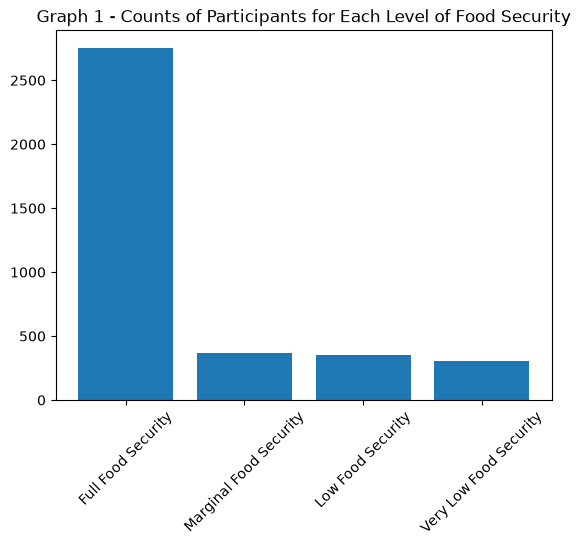

In [41]:
food_security_order = ['Full Food Security', 'Marginal Food Security', 'Low Food Security', 'Very Low Food Security']
counts = final_df["Adult_Food_Security"].value_counts().reindex(food_security_order)

plt.bar(counts.index, counts.values)
plt.title("Graph 1 - Counts of Participants for Each Level of Food Security")
plt.xticks(rotation = 45)
plt.savefig("Pres 2 Graphs/Graph 1.png")
plt.show()

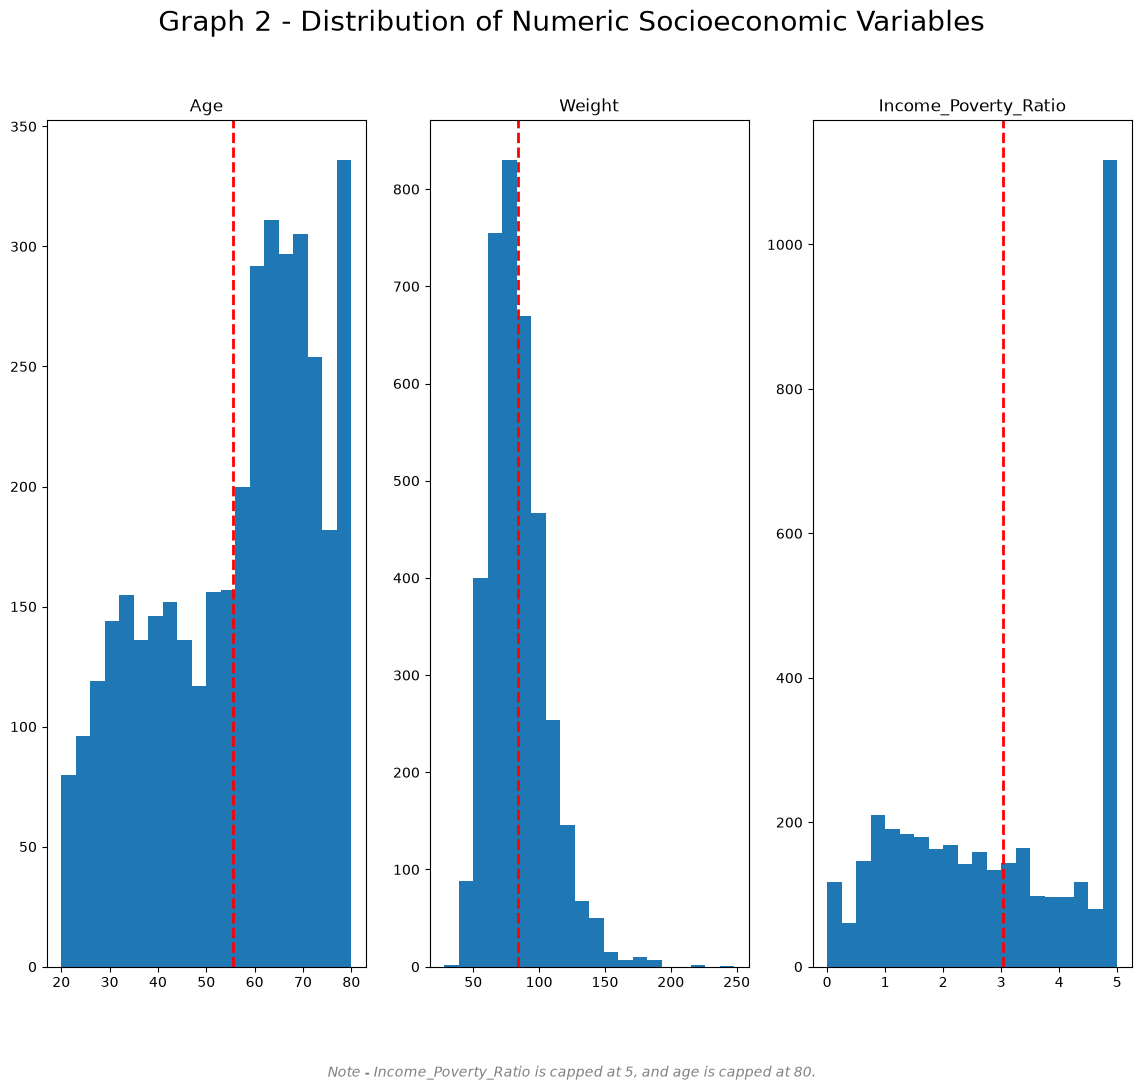

In [42]:
numeric_demo_list = ["Age", "Weight", "Income_Poverty_Ratio"]

fig, axs = plt.subplots(1, 3, figsize = (14, 11))
for i, col in enumerate(numeric_demo_list):
    axs[i].hist(final_df[col], bins = 20)
    axs[i].set_title(f"{col}")
    axs[i].axvline(np.mean(final_df[col]), color = 'red', linestyle = 'dashed', linewidth = 2)

plt.suptitle("Graph 2 - Distribution of Numeric Socioeconomic Variables", fontsize = 20)
plt.figtext(0.5, 0.01, "Note - Income_Poverty_Ratio is capped at 5, and age is capped at 80.", 
            ha = 'center', fontsize = 10, style = 'italic', color = 'gray')
plt.savefig("Pres 2 Graphs/Graph 2.png")
plt.show()

In [43]:
#will need this for marital status and education level variables
over_20_df = final_df[~final_df["Marital_Status"].isin(["Don't know", "Refused"])]
over_20_df.shape

(3769, 45)

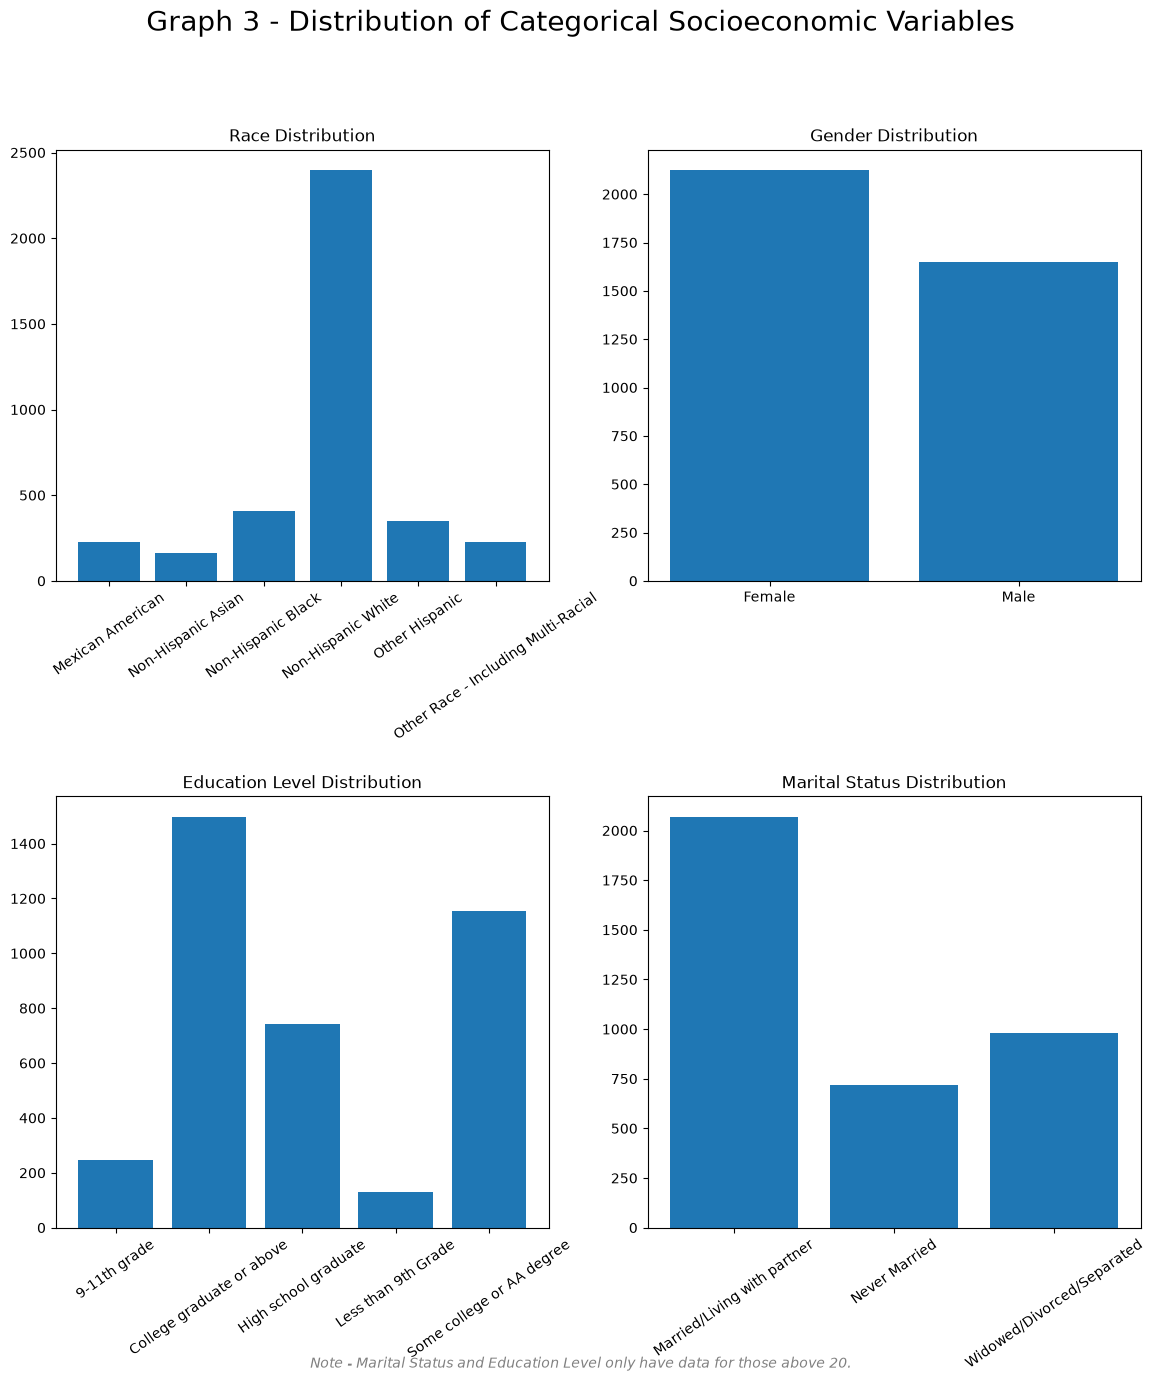

In [44]:
fig, axs = plt.subplots(2, 2, figsize = (14, 14))

keys, counts = np.unique(final_df["Race"], return_counts = True)
axs[0, 0].bar(keys, counts)
axs[0, 0].set_title("Race Distribution")
axs[0, 0].tick_params(axis = "x", labelrotation = 35)

keys, counts = np.unique(final_df["Gender"], return_counts = True)
axs[0, 1].bar(keys, counts)
axs[0, 1].set_title("Gender Distribution")

keys, counts = np.unique(over_20_df["Education_Level"], return_counts = True)
axs[1, 0].bar(keys, counts)
axs[1, 0].set_title("Education Level Distribution")
axs[1, 0].tick_params(axis = "x", labelrotation = 35)

keys, counts = np.unique(over_20_df["Marital_Status"], return_counts = True)
axs[1, 1].bar(keys, counts)
axs[1, 1].set_title("Marital Status Distribution")
axs[1, 1].tick_params(axis = "x", labelrotation = 35)


plt.suptitle("Graph 3 - Distribution of Categorical Socioeconomic Variables", fontsize = 20)
fig.subplots_adjust(hspace = 0.5, wspace = 0.2)
plt.figtext(0.5, 0.01, "Note - Marital Status and Education Level only have data for those above 20.", 
            ha = 'center', fontsize = 10, style = 'italic', color = 'gray')
plt.savefig("Pres 2 Graphs/Graph 3.png")
plt.show()

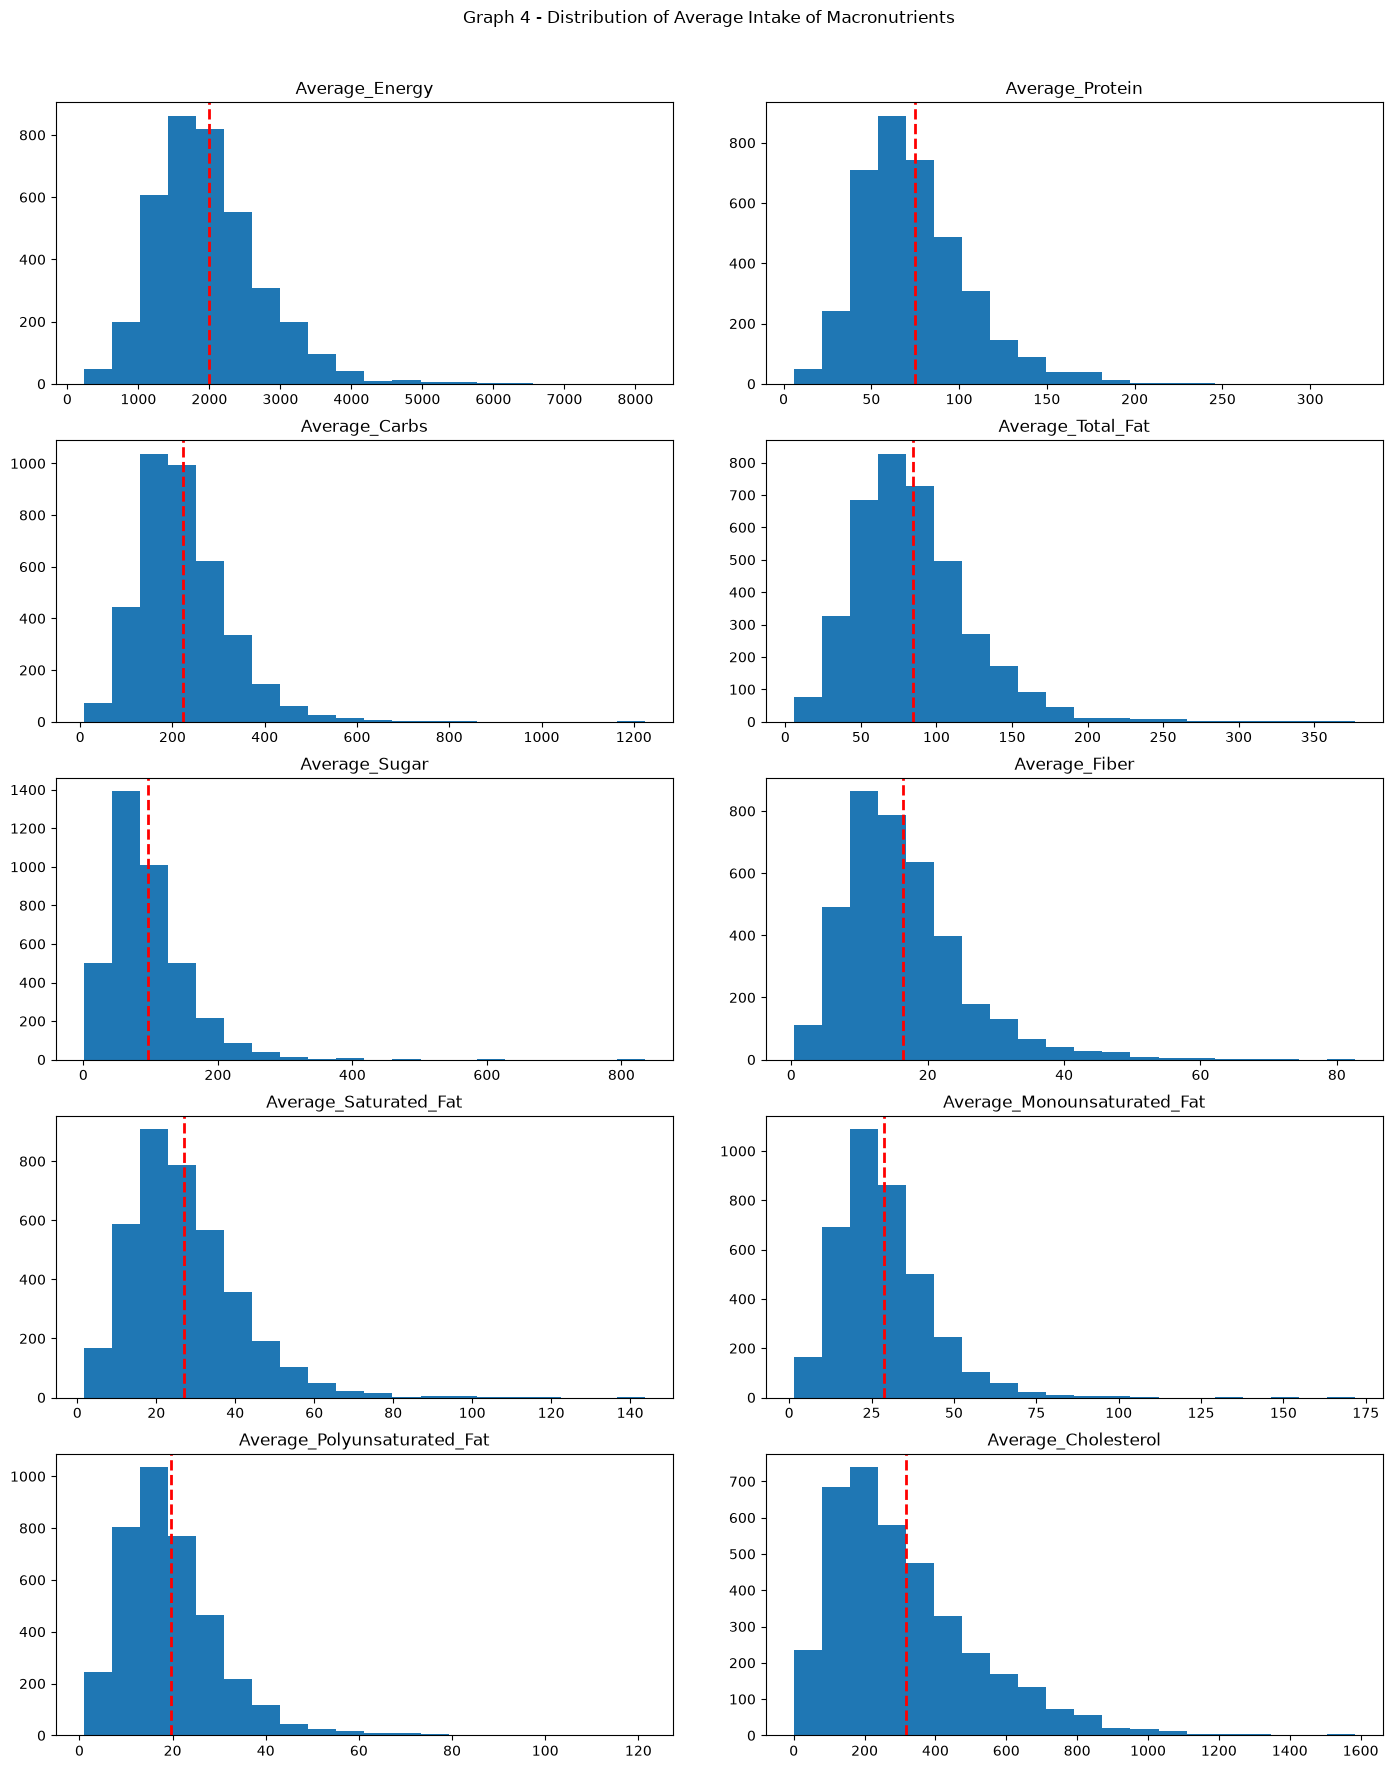

In [45]:
fig, axs = plt.subplots(5, 2, figsize = (14, 18))
fig.tight_layout(rect = [0, 0, 1, 0.94])
axs = axs.flatten()

for i, col in enumerate(macronutrients):
    axs[i].hist(final_df[col], bins = 20)
    axs[i].set_title(f"{col}")
    axs[i].axvline(np.mean(final_df[col]), color = 'red', linestyle = 'dashed', linewidth = 2)

plt.suptitle("Graph 4 - Distribution of Average Intake of Macronutrients")
fig.subplots_adjust(hspace = 0.2, wspace = 0.15)
plt.savefig("Pres 2 Graphs/Graph 4.png")
plt.show()

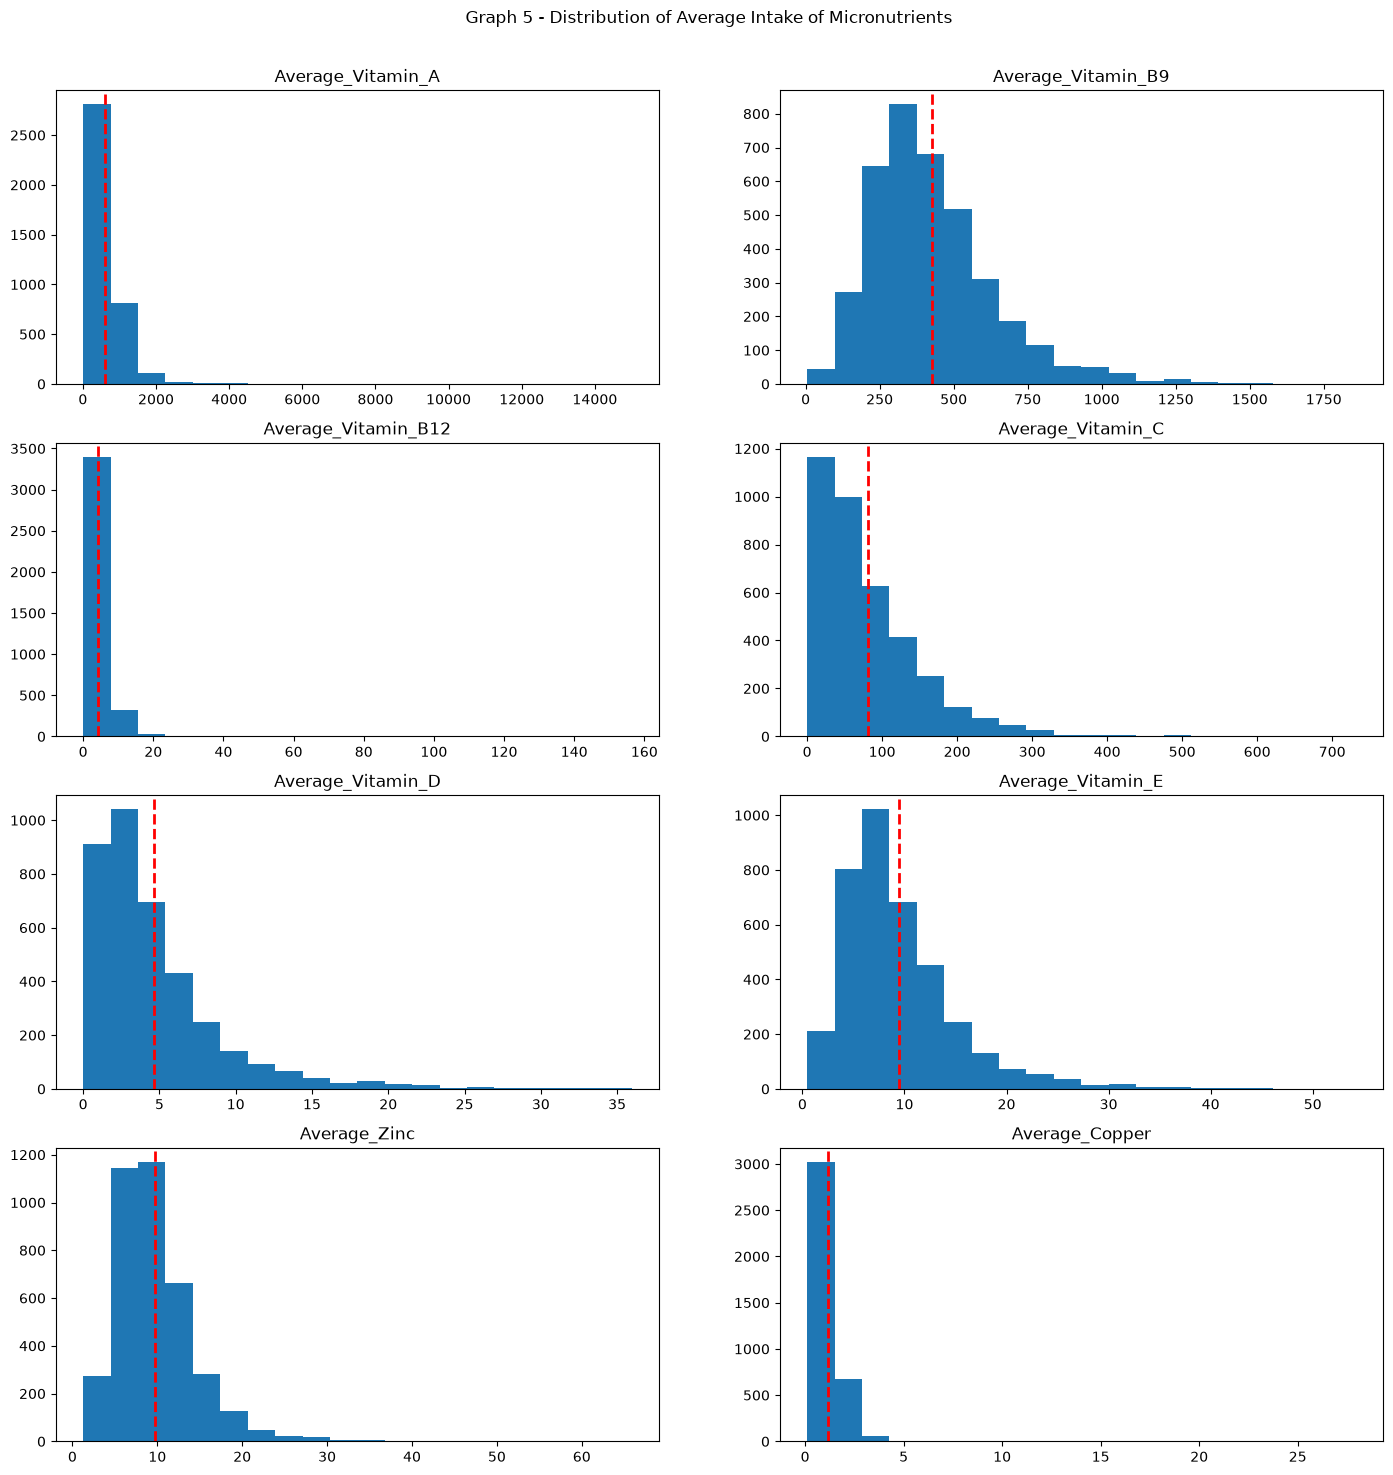

In [46]:
fig, axs = plt.subplots(4, 2, figsize = (14, 15))
fig.tight_layout(rect = [0, 0, 1, 0.94])
axs = axs.flatten()

for i, col in enumerate(micronutrients):
    axs[i].hist(final_df[col], bins = 20)
    axs[i].set_title(f"{col}")
    axs[i].axvline(np.mean(final_df[col]), color = 'red', linestyle = 'dashed', linewidth = 2)

plt.suptitle("Graph 5 - Distribution of Average Intake of Micronutrients")
fig.subplots_adjust(hspace = 0.2, wspace = 0.2)
plt.savefig("Pres 2 Graphs/Graph 5.png")
plt.show()

/tmp/ipykernel_1468/1535061750.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(food_security_labels)
/tmp/ipykernel_1468/1535061750.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(food_security_labels)
/tmp/ipykernel_1468/1535061750.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(food_security_labels)
/tmp/ipykernel_1468/1535061750.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(food_security_labels)
/tmp

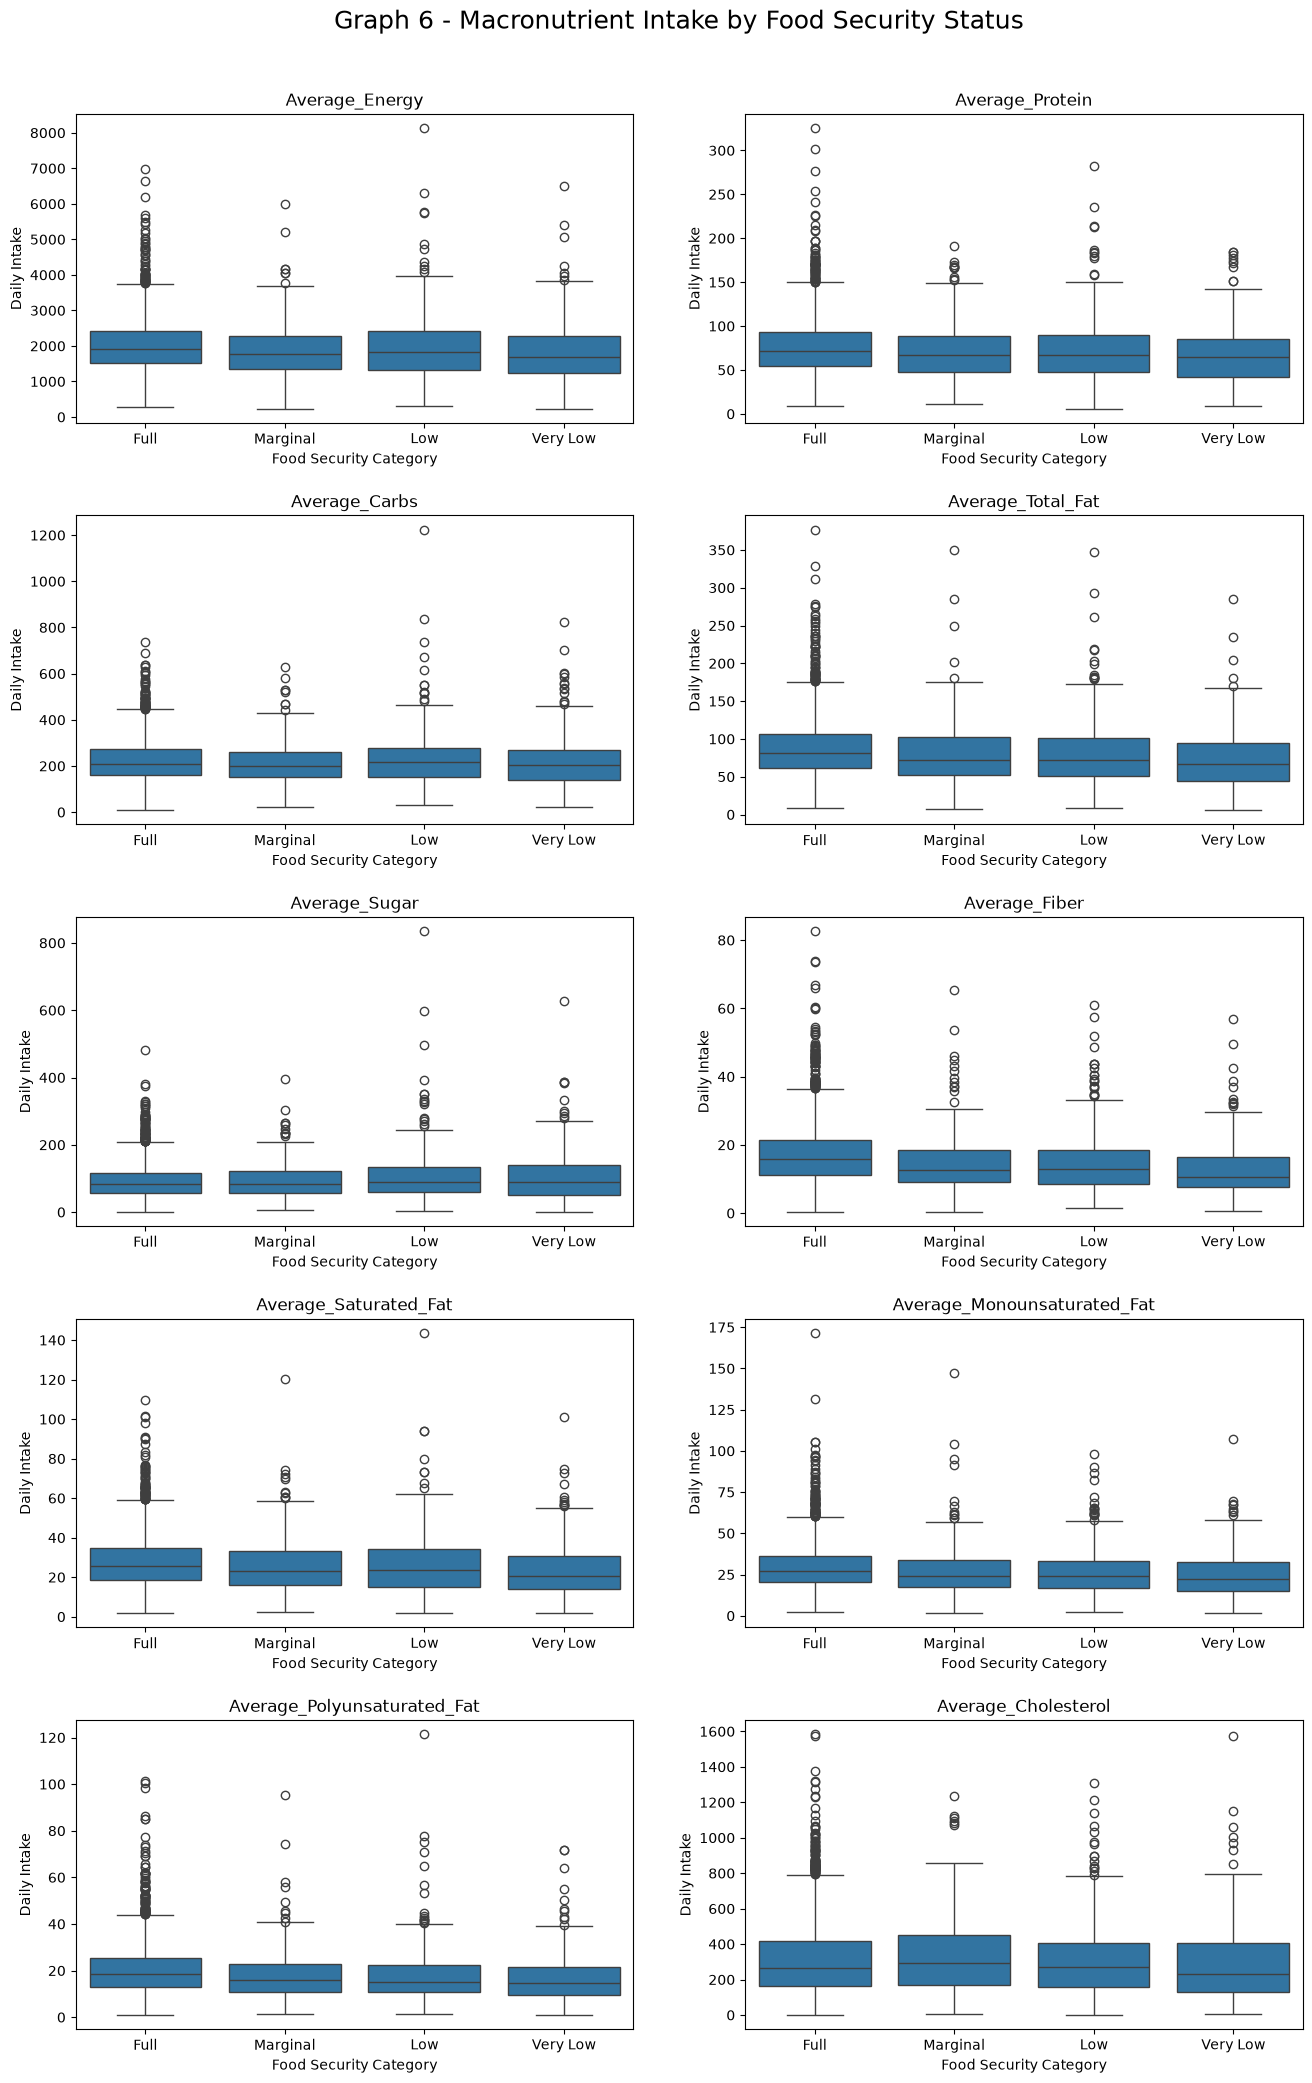

In [47]:
food_security_labels = [
    "Full",
    "Marginal",
    "Low",
    "Very Low"
]

fig, axs = plt.subplots(5, 2, figsize = (13, 21))
fig.tight_layout(rect = [0, 0, 1, 0.94])
axs = axs.flatten()

for i, col in enumerate(macronutrients):
    sns.boxplot(
        data = final_df,
        x = "Adult_Food_Security",
        order = food_security_order,
        y = col,
        ax = axs[i]
)
    
    axs[i].set_title(f"{col}")
    axs[i].set_xlabel("Food Security Category")
    axs[i].set_xticklabels(food_security_labels)
    axs[i].set_ylabel("Daily Intake")

fig.subplots_adjust(hspace = 0.3, wspace = 0.2)
fig.suptitle("Graph 6 - Macronutrient Intake by Food Security Status", fontsize = 18)
plt.savefig("Pres 2 Graphs/Graph 6.png")
plt.show()

/tmp/ipykernel_1468/1326495910.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(food_security_labels)
/tmp/ipykernel_1468/1326495910.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(food_security_labels)
/tmp/ipykernel_1468/1326495910.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(food_security_labels)
/tmp/ipykernel_1468/1326495910.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(food_security_labels)
/tmp

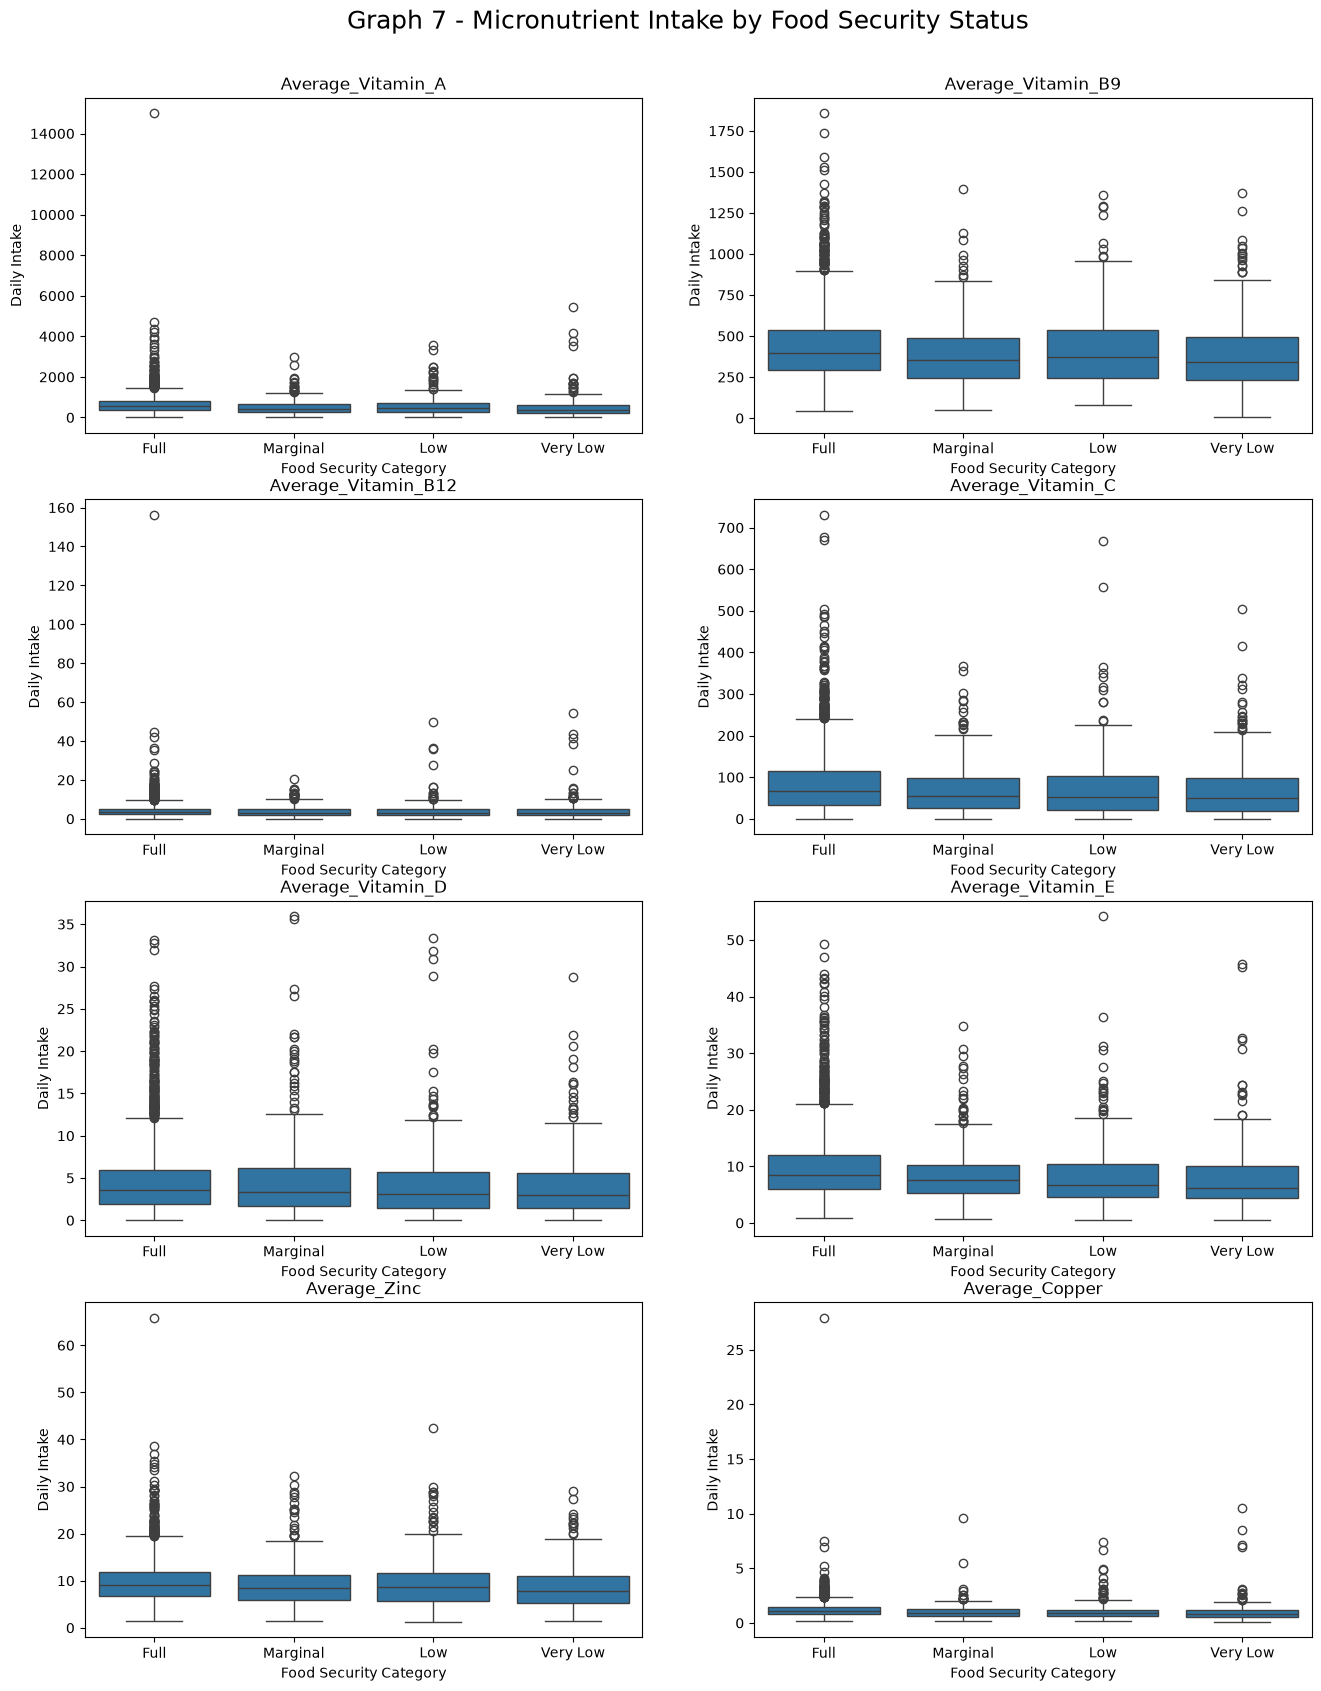

In [48]:
fig, axs = plt.subplots(4, 2, figsize = (13, 17))
fig.tight_layout(rect = [0, 0, 1, 0.94])
axs = axs.flatten()

for i, col in enumerate(micronutrients):
    sns.boxplot(
        data = final_df,
        x = "Adult_Food_Security",
        order = food_security_order,
        y = col,
        ax = axs[i]
)
    
    axs[i].set_title(f"{col}")
    axs[i].set_xlabel("Food Security Category")
    axs[i].set_xticklabels(food_security_labels)
    axs[i].set_ylabel("Daily Intake")

fig.subplots_adjust(hspace = 0.2, wspace = 0.2)
fig.suptitle("Graph 7 - Micronutrient Intake by Food Security Status", fontsize = 18)
plt.savefig("Pres 2 Graphs/Graph 7.png")
plt.show()

/tmp/ipykernel_1468/1028002961.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(food_security_labels)
/tmp/ipykernel_1468/1028002961.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(food_security_labels)
/tmp/ipykernel_1468/1028002961.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(food_security_labels)
/tmp/ipykernel_1468/1028002961.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(food_security_labels)
/tmp

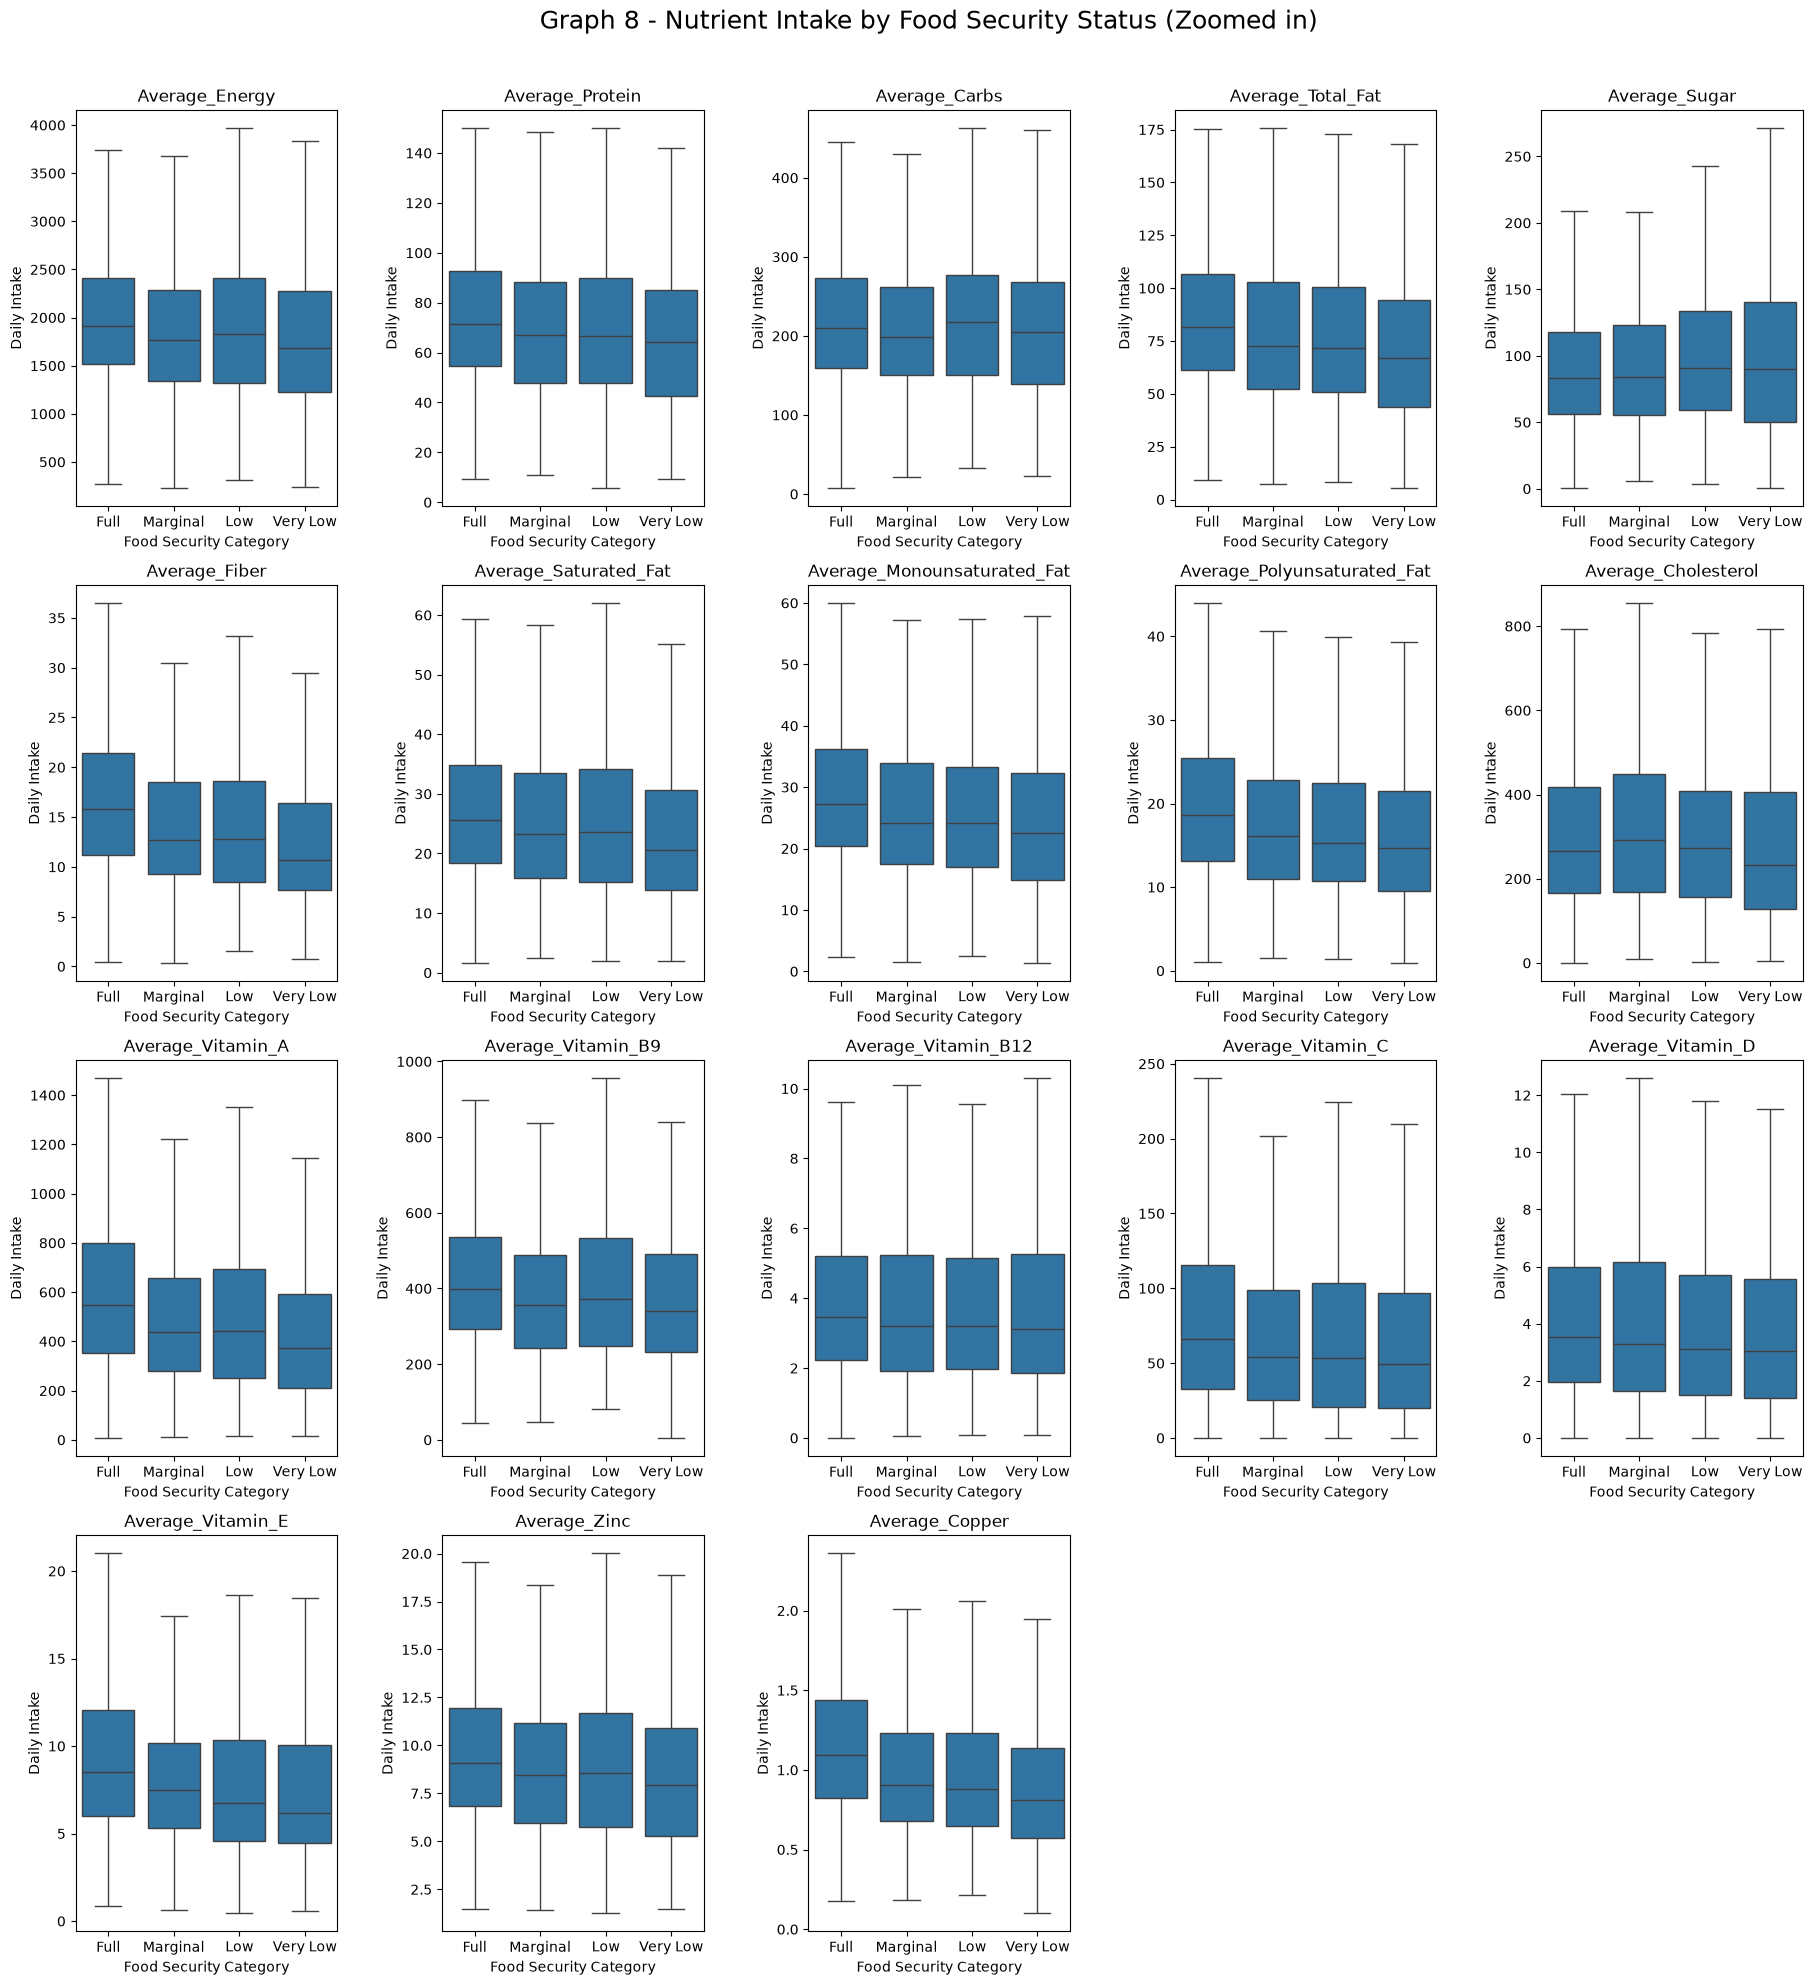

In [49]:
fig, axs = plt.subplots(4, 5, figsize = (18, 20))
fig.tight_layout(rect = [0, 0, 1, 0.94])
axs = axs.flatten()

for i, col in enumerate(nutrients):
    sns.boxplot(
        data = final_df,
        x = "Adult_Food_Security",
        order = food_security_order,
        y = col,
        ax = axs[i],
        showfliers = False
)
    
    axs[i].set_title(f"{col}")
    axs[i].set_xlabel("Food Security Category")
    axs[i].set_xticklabels(food_security_labels)
    axs[i].set_ylabel("Daily Intake")


for i in range(len(nutrients), len(axs)):
    axs[i].set_visible(False)

fig.subplots_adjust(hspace = 0.2, wspace = 0.4)
fig.suptitle("Graph 8 - Nutrient Intake by Food Security Status (Zoomed in)", fontsize = 18)
plt.savefig("Pres 2 Graphs/Graph 8.png")
plt.show()

/tmp/ipykernel_1468/1561318094.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(poverty_ratio_labels)
/tmp/ipykernel_1468/1561318094.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(poverty_ratio_labels)
/tmp/ipykernel_1468/1561318094.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(poverty_ratio_labels)
/tmp/ipykernel_1468/1561318094.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axs[i].set_xticklabels(poverty_ratio_labels)
/tmp

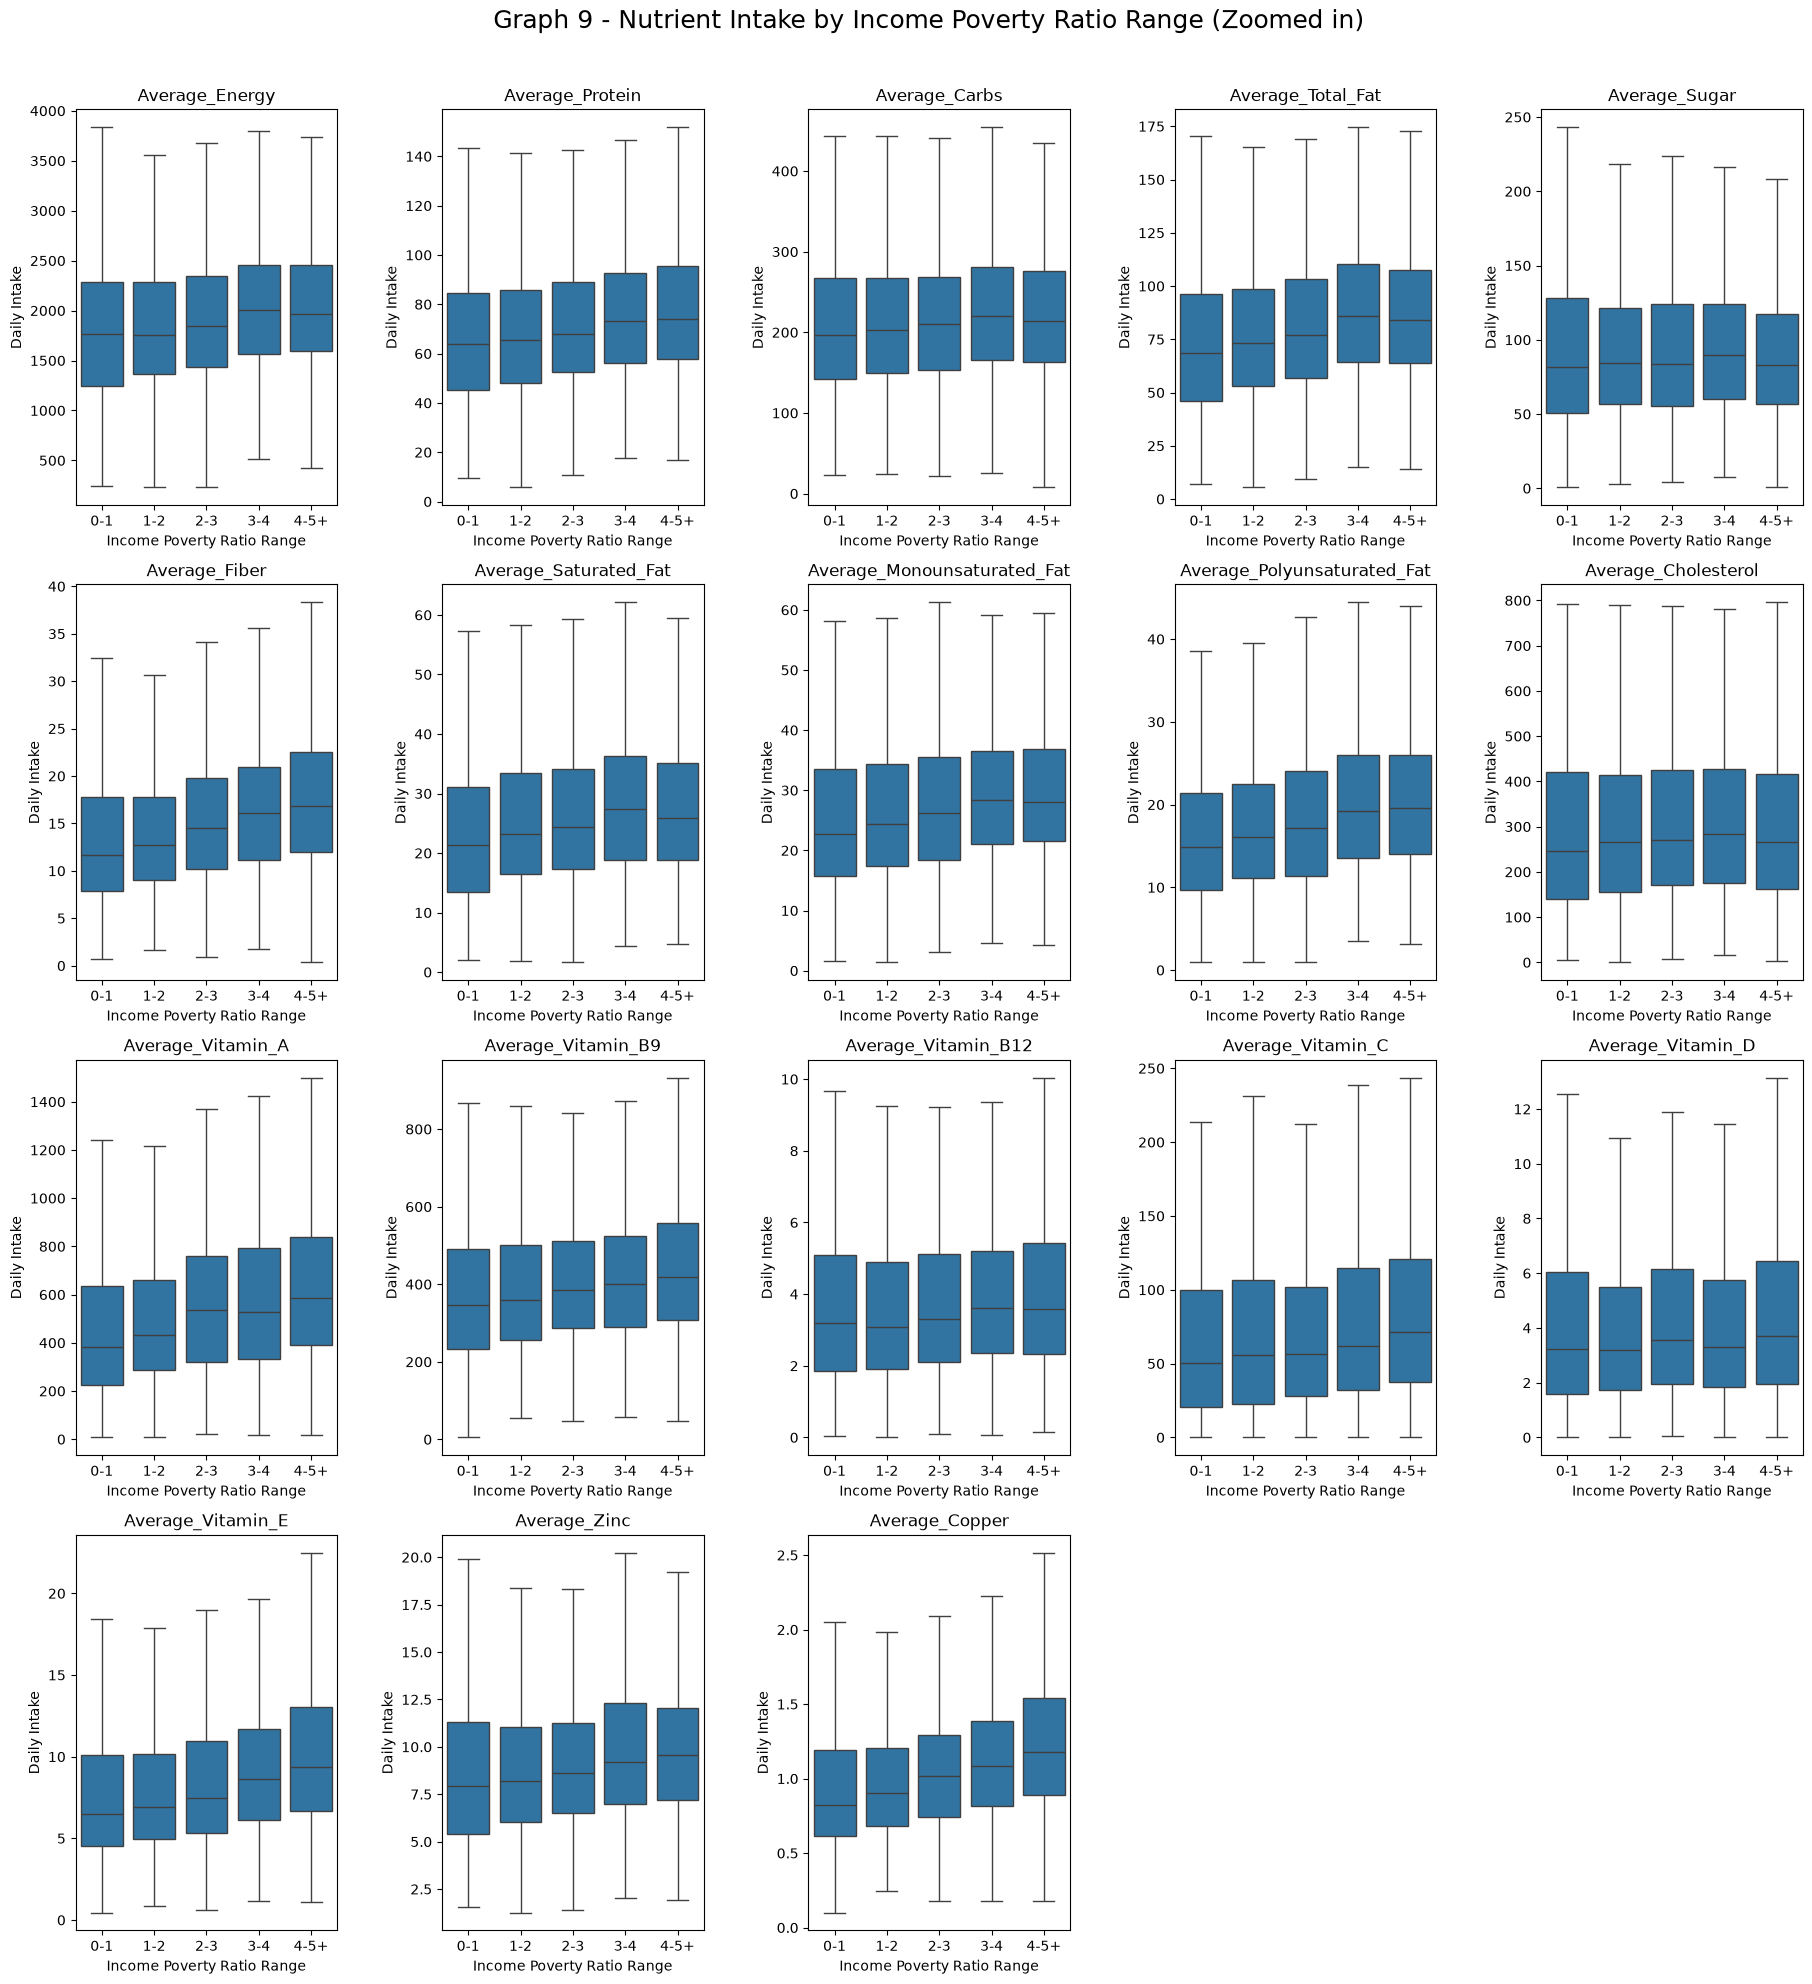

In [50]:
#note - income poverty ratio is calculated by family income (approximate if not given) divided by federal poverty guideline

final_df['Poverty_Ratio_Categorical'] = pd.cut(final_df['Income_Poverty_Ratio'], 
                                               bins = [0, 1, 2, 3, 4, 5], labels=['0-1', '1-2', "2-3", "3-4", "4-5+"], include_lowest = True)

poverty_ratio_labels = ['0-1', '1-2', "2-3", "3-4", "4-5+"]

fig, axs = plt.subplots(4, 5, figsize = (18, 20))
fig.tight_layout(rect = [0, 0, 1, 0.94])
axs = axs.flatten()

for i, col in enumerate(nutrients):
    sns.boxplot(
        data = final_df,
        x = "Poverty_Ratio_Categorical",
        y = col,
        ax = axs[i],
        showfliers = False
)
    
    axs[i].set_title(f"{col}")
    axs[i].set_xlabel("Income Poverty Ratio Range")
    axs[i].set_xticklabels(poverty_ratio_labels)
    axs[i].set_ylabel("Daily Intake")

for i in range(len(nutrients), len(axs)):
    axs[i].set_visible(False)

fig.subplots_adjust(hspace = 0.2, wspace = 0.4)
fig.suptitle("Graph 9 - Nutrient Intake by Income Poverty Ratio Range (Zoomed in)", fontsize = 18)
plt.savefig("Pres 2 Graphs/Graph 9.png")
plt.show()

Now that we have some graphs, we should continue by looking at some of the outliers. Some incredibly obvious outliers lie on the graphs of average energy, average sugar, average protein, average vitamin A, average vitamin B12, average vitamin E, average zinc, and average copper. due to the nature of the data, we must investigate whether or not these are simply data points of individuals who really love a certain nutrient, or if these are genuine errors before we decide to remove them or not. To look at outliers, we will take a look at the rows where these values lie and see if the rest of the data collected from that individual seems valid.

In [51]:
#for i in nutrients:
#    outlier_df = final_df.sort_values(by = i, ascending = False)
#    print(i, "\n")
#    print(outlier_df.head(20))

#wayyyyy too long   

In [52]:
nutrients = macronutrients + micronutrients

for nutrient in nutrients:
    q1 = final_df[nutrient].quantile(0.25)
    q3 = final_df[nutrient].quantile(0.75)
    iqr = q3 - q1

    upper_limit = q3 + 3 * iqr

    outliers = final_df[final_df[nutrient] > upper_limit]

    print(nutrient, len(outliers))

Average_Energy 15
Average_Protein 14
Average_Carbs 12
Average_Total_Fat 19
Average_Sugar 24
Average_Fiber 21
Average_Saturated_Fat 13
Average_Monounsaturated_Fat 24
Average_Polyunsaturated_Fat 30
Average_Cholesterol 12
Average_Vitamin_A 46
Average_Vitamin_B9 20
Average_Vitamin_B12 65
Average_Vitamin_C 29
Average_Vitamin_D 78
Average_Vitamin_E 46
Average_Zinc 30
Average_Copper 36


Overall, looking at the outliers does not give any indication of the data being bad; the consumption of macronutrients and micronutrients done by the individuals with the highest levels of consumption seem to be simply abnormal. Perhaps these individuals just really enjoy Vitamin A! In any case, when it is necessary, we will compare the difference in results when outliers are removed compared to when they are included.

In [53]:
#Nutrients per 1,000 kcal:
density_nutrients = []

for col in nutrients[1:]:
    new_col = col.replace('Average_', '') + '_per_1000kcal'
    final_df[new_col] = final_df[col] / final_df['Average_Energy'] * 1000
    density_nutrients.append(new_col)

#Bonferroni Correction (18 tests):
bonferroni_cutoff = 0.05 / (len(density_nutrients) + 1)
print("Bonferroni p-value cutoff:", round(bonferroni_cutoff, 4))

Bonferroni p-value cutoff: 0.0028


In [54]:
#T-Tests (Full vs Very Low) and Kruskal-Wallis (all 4 groups):
t_test_results = []

for i in ['Average_Energy'] + density_nutrients:
    secure = final_df[final_df["Adult_Food_Security"] == "Full Food Security"][i].dropna()
    insecure = final_df[final_df["Adult_Food_Security"] == "Very Low Food Security"][i].dropna()
    result = ttest_ind(secure, insecure, equal_var=False)

    groups = [final_df[final_df["Adult_Food_Security"] == level][i].dropna() for level in food_security_order]
    kw_result = kruskal(*groups)

    t_test_results.append({
        'Nutrient': i,
        'Mean_Full': secure.mean(),
        'Mean_Very_Low': insecure.mean(),
        't_statistic': result.statistic,
        't_test_p_value': result.pvalue,
        'Kruskal_p_value': kw_result.pvalue,
        'Significant_after_Bonferroni': result.pvalue < bonferroni_cutoff
    })

t_test_df = pd.DataFrame(t_test_results).sort_values('t_test_p_value')
t_test_df.round(4)

,Nutrient,Mean_Full,Mean_Very_Low,t_statistic,t_test_p_value,Kruskal_p_value,Significant_after_Bonferroni
5,Fiber_per_1000kcal,8.7464,7.1878,7.8706,0.0000,0.0000,True
4,Sugar_per_1000kcal,45.8029,56.6826,-6.3093,0.0000,0.0000,True
2,Carbs_per_1000kcal,110.6273,120.0153,-5.5391,0.0000,0.0000,True
3,Total_Fat_per_1000kcal,42.7376,39.9371,4.7901,0.0000,0.0000,True
7,Monounsaturated_Fat_per_1000kcal,14.5487,13.6162,3.7861,0.0002,0.0000,True
6,Saturated_Fat_per_1000kcal,13.5630,12.6690,3.7617,0.0002,0.0006,True
0,Average_Energy,2027.3943,1838.6957,3.5975,0.0004,0.0000,True
8,Polyunsaturated_Fat_per_1000kcal,10.0311,9.2381,3.4868,0.0005,0.0000,True
15,Vitamin_E_per_1000kcal,4.9382,4.4321,2.7332,0.0066,0.0000,False
10,Vitamin_A_per_1000kcal,328.2610,282.2142,2.6678,0.0080,0.0000,False


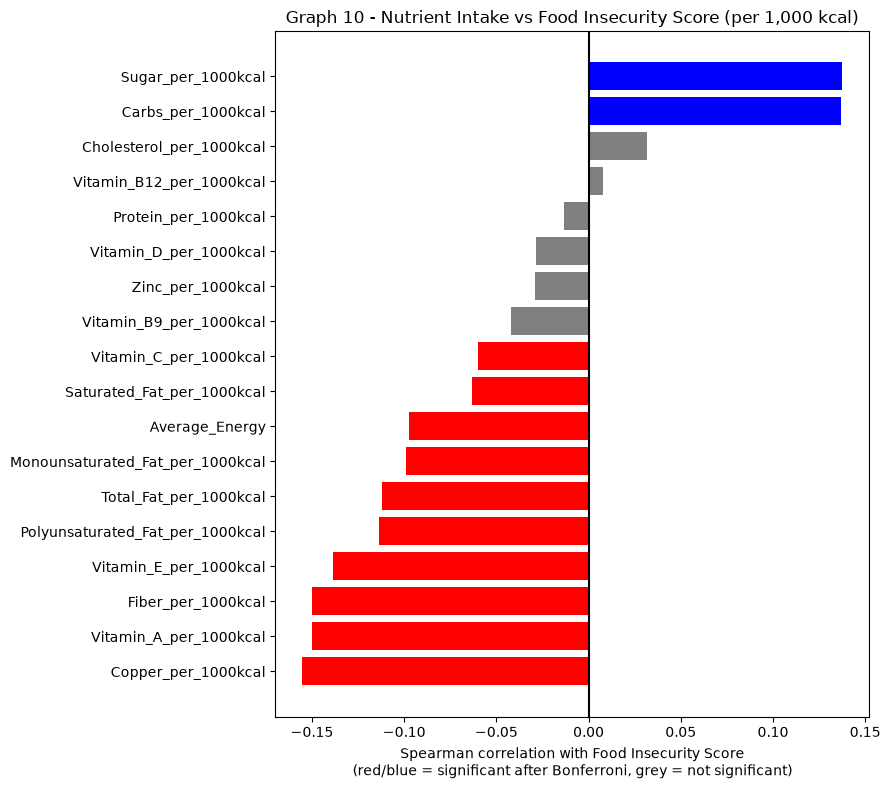

In [55]:
#Graph 10 - Spearman Correlation between Food Insecurity Score and Nutrients:
spearman_results = []

for i in ['Average_Energy'] + density_nutrients:
    rho, p_value = spearmanr(final_df['Food_Insecurity_Score'], final_df[i], nan_policy = 'omit')
    spearman_results.append({'Nutrient': i, 'Spearman_rho': rho, 'p_value': p_value})

spearman_df = pd.DataFrame(spearman_results).sort_values('Spearman_rho')
colors = np.where(spearman_df['p_value'] >= bonferroni_cutoff, 'grey', 
                  np.where(spearman_df['Spearman_rho'] < 0, 'red', 'blue'))

plt.figure(figsize = (9, 8))
plt.barh(spearman_df['Nutrient'], spearman_df['Spearman_rho'], color = colors)
plt.axvline(0, color = 'black')
plt.xlabel("Spearman correlation with Food Insecurity Score\n(red/blue = significant after Bonferroni, grey = not significant)")
plt.title("Graph 10 - Nutrient Intake vs Food Insecurity Score (per 1,000 kcal)")
plt.tight_layout()
plt.savefig("Pres 2 Graphs/Graph 10.png")
plt.show()

In [56]:
final_df.columns

Index(['ID', 'Race', 'Gender', 'Country_of_Birth', 'Age', 'Weight',
       'Education_Level', 'Marital_Status', 'Income_Poverty_Ratio',
       'Total_People_in_Household', 'Family_Monthly_Poverty_Level_Category',
       'Adult_Food_Security', 'Food_Insecurity_Score',
       'Cannot_Afford_Balance_Meals', 'Adults_Who_Skip_Meals',
       'Hungry_and_Didn't_Eat', 'Receiving_Food_Assistaince',
       'Received_Emergency_Food', 'Weight_Loss_Diet', 'Special_Diet',
       'Average_Energy', 'Average_Protein', 'Average_Carbs',
       'Average_Total_Fat', 'Average_Sugar', 'Average_Fiber',
       'Average_Saturated_Fat', 'Average_Monounsaturated_Fat',
       'Average_Polyunsaturated_Fat', 'Average_Cholesterol',
       'Average_Vitamin_A', 'Average_Vitamin_B9', 'Average_Vitamin_B12',
       'Average_Vitamin_C', 'Average_Vitamin_D', 'Average_Vitamin_E',
       'Average_Zinc', 'Average_Copper', 'Dietary_Recall_Status_Day_1',
       'Dietary_Recall_Status_Day_2', 'Number_of_Dietary_Recall_Day',
     

In [ ]:
design = svy.Design(
    stratum = "Masked_variance_pseudo-stratum",
    psu = "Masked_variance_pseudo-PSU",
    wgt = "Dietary_Day_1_Sample_Weight"
)

sample = svy.Sample(
    data = final_df,
    design = design
)